# ECC skalyar ko‘paytirish — yagona tajriba (Jupyter versiyasi)

Kataklarni **yuqoridan pastga, ketma-ket** ishga tushiring: menyudan **Run → Run All Cells** (yoki **Kernel → Restart & Run All**).

Natijalar shu notebook turgan papkadagi **`ecbench_natijalar`** papkasiga saqlanadi. Oxirgi katak hammasini **`ecbench_natijalar.zip`** fayliga joylaydi va uning to‘liq manzilini chiqaradi — shu zip faylni yuboring.

O‘lchash vaqtida brauzerdagi boshqa tablarni va og‘ir dasturlarni yoping, noutbukni zaryadga ulang.

## 1. Kutubxonalarni o‘rnatish
Xato chiqsa ham davom eting — oxirida qaysi biri o‘rnatilmagani ko‘rsatiladi.

In [13]:
import sys, subprocess, importlib
paketlar = {"gmpy2": "gmpy2", "coincurve": "coincurve", "cryptography": "cryptography",
            "numpy": "numpy", "pandas": "pandas", "scipy": "scipy",
            "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
for modul, pip_nomi in paketlar.items():
    try:
        importlib.import_module(modul)
        print(f"[bor]        {pip_nomi}")
    except ImportError:
        print(f"[o'rnatilmoqda] {pip_nomi} ...", end=" ")
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_nomi],
                           capture_output=True, text=True)
        print("OK" if r.returncode == 0 else "XATO:\n" + r.stderr[-800:])

[bor]        gmpy2
[bor]        coincurve
[bor]        cryptography
[bor]        numpy
[bor]        pandas
[bor]        scipy
[bor]        scikit-learn
[bor]        matplotlib


## 2. Muhit tekshiruvi
Agar `gmpy2` yoki `coincurve` qarshisida **YO‘Q** chiqsa, **Kernel → Restart** qilib, yana **Run All** bosing. Baribir YO‘Q bo‘lsa — ularsiz ham ishlaydi, faqat shu natijani menga yozing.

In [14]:
import os, platform
importlib.invalidate_caches()
print("Python      :", sys.version.split()[0], "|", sys.executable)
print("Platforma   :", platform.platform())
print("Ishchi papka:", os.getcwd())
for m in ["gmpy2", "coincurve", "cryptography", "numpy", "pandas", "scipy", "sklearn", "matplotlib"]:
    try:
        mod = importlib.import_module(m)
        print(f"  {m:13s}: {getattr(mod, '__version__', 'bor')}")
    except Exception as e:
        print(f"  {m:13s}: YO'Q  ({e.__class__.__name__})")

Python      : 3.13.18 | C:\Users\User\.conda\envs\crypto313\python.exe
Platforma   : Windows-11-10.0.26200-SP0
Ishchi papka: C:\Users\User
  gmpy2        : 2.3.2
  coincurve    : 21.0.0
  cryptography : 50.0.2
  numpy        : 2.5.4
  pandas       : 3.1.0
  scipy        : 1.18.1
  sklearn      : 1.9.1
  matplotlib   : 3.11.2


## 3. Dastur modullari
Quyidagi kataklar dastur fayllarini ishchi papkaga yozadi (o‘zgartirish shart emas).

In [15]:
%%writefile ec_core.py
"""
ec_core.py — elliptik egri chiziq arifmetikasi (qisqa Veyershtrass shakli, Fp).

* Jacobian koordinatalar: (X, Y, Z) -> affin (X/Z^2, Y/Z^3); cheksizlik nuqtasi = None.
* Formulalar Explicit-Formulas Database (EFD, Bernstein–Lange) dan olingan:
    - dbl-2009-l   (a = 0)   : 2M + 5S
    - dbl-2001-b   (a = -3)  : 3M + 5S
    - dbl-2007-bl  (umumiy a): 1M + 8S + 1*a
    - add-2007-bl  (J + J)   : 11M + 5S
    - madd-2007-bl (J + A)   : 7M + 4S
* gmpy2 o'rnatilgan bo'lsa, maydon elementlari mpz bo'ladi (2–4 marta tezroq).
* CountingCurve — har bir amalni sanaydigan variant (vaqt o'lchashda ishlatilmaydi).
"""
from __future__ import annotations

try:
    import gmpy2
    from gmpy2 import mpz
    HAVE_GMPY2 = True

    def _inv(x, p):
        return gmpy2.invert(x, p)
except ImportError:  # sof Python
    HAVE_GMPY2 = False
    mpz = int

    def _inv(x, p):
        return pow(x, -1, p)


# --------------------------------------------------------------------------- #
#  Egri chiziq parametrlari
# --------------------------------------------------------------------------- #
CURVES = {
    "secp256k1": dict(
        p=2**256 - 2**32 - 977,
        a=0,
        b=7,
        n=0xFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFEBAAEDCE6AF48A03BBFD25E8CD0364141,
        Gx=0x79BE667EF9DCBBAC55A06295CE870B07029BFCDB2DCE28D959F2815B16F81798,
        Gy=0x483ADA7726A3C4655DA4FBFC0E1108A8FD17B448A68554199C47D08FFB10D4B8,
        # GLV endomorfizmi: phi(x, y) = (beta*x, y) = [lam]P
        lam=0x5363AD4CC05C30E0A5261C028812645A122E22EA20816678DF02967C1B23BD72,
        beta=0x7AE96A2B657C07106E64479EAC3434E99CF0497512F58995C1396C28719501EE,
    ),
    "P-256": dict(
        p=2**256 - 2**224 + 2**192 + 2**96 - 1,
        a=-3,
        b=0x5AC635D8AA3A93E7B3EBBD55769886BC651D06B0CC53B0F63BCE3C3E27D2604B,
        n=0xFFFFFFFF00000000FFFFFFFFFFFFFFFFBCE6FAADA7179E84F3B9CAC2FC632551,
        Gx=0x6B17D1F2E12C4247F8BCE6E563A440F277037D812DEB33A0F4A13945D898C296,
        Gy=0x4FE342E2FE1A7F9B8EE7EB4A7C0F9E162BCE33576B315ECECBB6406837BF51F5,
    ),
    # O'quv egri chizig'i (faqat to'g'rilik testi uchun): y^2 = x^3 + 2x + 2 (mod 17)
    "toy17": dict(p=17, a=2, b=2, n=19, Gx=5, Gy=1),
}


class Curve:
    """Jacobian arifmetikasi (sanash yo'q — vaqt o'lchash uchun)."""

    def __init__(self, name: str):
        c = CURVES[name]
        self.name = name
        self.p = mpz(c["p"])
        self.a_int = c["a"]
        self.a = mpz(c["a"] % c["p"])
        self.b = mpz(c["b"])
        self.n = int(c["n"])
        self.G = (mpz(c["Gx"]), mpz(c["Gy"]))
        self.lam = c.get("lam")
        self.beta = mpz(c["beta"]) if "beta" in c else None
        self.field_bytes = (int(self.p).bit_length() + 7) // 8
        if self.a_int == 0:
            self.dbl = self._dbl_a0
        elif self.a_int == -3:
            self.dbl = self._dbl_am3
        else:
            self.dbl = self._dbl_gen

    # ------------------------------------------------------------------ #
    def on_curve(self, P) -> bool:
        if P is None:
            return True
        x, y = P
        p = self.p
        return (y * y - (x * x * x + self.a * x + self.b)) % p == 0

    @staticmethod
    def to_jac(P):
        return None if P is None else (P[0], P[1], mpz(1))

    def neg_aff(self, P):
        return None if P is None else (P[0], (-P[1]) % self.p)

    def to_affine(self, J):
        if J is None:
            return None
        X, Y, Z = J
        p = self.p
        zi = _inv(Z, p)
        zi2 = zi * zi % p
        return (X * zi2 % p, Y * zi2 * zi % p)

    def batch_to_affine(self, Js):
        """Montgomery hiylasi: n ta nuqta uchun 1 ta inversiya + 3(n-1) M, keyin har biriga 1S+3M."""
        p = self.p
        pts = [J for J in Js]
        if not pts:
            return []
        acc = [None] * len(pts)
        prod = mpz(1)
        for i, J in enumerate(pts):
            acc[i] = prod
            prod = prod * J[2] % p
        inv = _inv(prod, p)
        out = [None] * len(pts)
        for i in range(len(pts) - 1, -1, -1):
            X, Y, Z = pts[i]
            zi = inv * acc[i] % p
            inv = inv * Z % p
            zi2 = zi * zi % p
            out[i] = (X * zi2 % p, Y * zi2 * zi % p)
        return out

    # ------------------------- ikkilantirish -------------------------- #
    def _dbl_a0(self, J):  # dbl-2009-l
        if J is None:
            return None
        X1, Y1, Z1 = J
        if Y1 == 0:
            return None
        p = self.p
        A = X1 * X1 % p
        B = Y1 * Y1 % p
        C = B * B % p
        t = X1 + B
        D = 2 * (t * t - A - C) % p
        E = 3 * A % p
        F = E * E % p
        X3 = (F - 2 * D) % p
        Y3 = (E * (D - X3) - 8 * C) % p
        Z3 = 2 * Y1 * Z1 % p
        return (X3, Y3, Z3)

    def _dbl_am3(self, J):  # dbl-2001-b
        if J is None:
            return None
        X1, Y1, Z1 = J
        if Y1 == 0:
            return None
        p = self.p
        delta = Z1 * Z1 % p
        gamma = Y1 * Y1 % p
        beta = X1 * gamma % p
        alpha = 3 * (X1 - delta) * (X1 + delta) % p
        X3 = (alpha * alpha - 8 * beta) % p
        t = Y1 + Z1
        Z3 = (t * t - gamma - delta) % p
        Y3 = (alpha * (4 * beta - X3) - 8 * gamma * gamma) % p
        return (X3, Y3, Z3)

    def _dbl_gen(self, J):  # dbl-2007-bl
        if J is None:
            return None
        X1, Y1, Z1 = J
        if Y1 == 0:
            return None
        p = self.p
        XX = X1 * X1 % p
        YY = Y1 * Y1 % p
        YYYY = YY * YY % p
        ZZ = Z1 * Z1 % p
        t = X1 + YY
        S = 2 * (t * t - XX - YYYY) % p
        M = (3 * XX + self.a * ZZ * ZZ) % p
        T = (M * M - 2 * S) % p
        Y3 = (M * (S - T) - 8 * YYYY) % p
        t = Y1 + Z1
        Z3 = (t * t - YY - ZZ) % p
        return (T, Y3, Z3)

    # --------------------------- qo'shish ----------------------------- #
    def add(self, J1, J2):  # add-2007-bl
        if J1 is None:
            return J2
        if J2 is None:
            return J1
        X1, Y1, Z1 = J1
        X2, Y2, Z2 = J2
        p = self.p
        Z1Z1 = Z1 * Z1 % p
        Z2Z2 = Z2 * Z2 % p
        U1 = X1 * Z2Z2 % p
        U2 = X2 * Z1Z1 % p
        S1 = Y1 * Z2 * Z2Z2 % p
        S2 = Y2 * Z1 * Z1Z1 % p
        H = (U2 - U1) % p
        r = 2 * (S2 - S1) % p
        if H == 0:
            if r == 0:
                return self.dbl(J1)
            return None
        I = 4 * H * H % p
        Jv = H * I % p
        V = U1 * I % p
        X3 = (r * r - Jv - 2 * V) % p
        Y3 = (r * (V - X3) - 2 * S1 * Jv) % p
        t = Z1 + Z2
        Z3 = (t * t - Z1Z1 - Z2Z2) * H % p
        return (X3, Y3, Z3)

    def madd(self, J1, A2):  # madd-2007-bl, A2 affin
        if A2 is None:
            return J1
        if J1 is None:
            return (A2[0], A2[1], mpz(1))
        X1, Y1, Z1 = J1
        X2, Y2 = A2
        p = self.p
        Z1Z1 = Z1 * Z1 % p
        U2 = X2 * Z1Z1 % p
        S2 = Y2 * Z1 * Z1Z1 % p
        H = (U2 - X1) % p
        r = 2 * (S2 - Y1) % p
        if H == 0:
            if r == 0:
                return self.dbl(J1)
            return None
        HH = H * H % p
        I = 4 * HH
        Jv = H * I % p
        V = X1 * I % p
        X3 = (r * r - Jv - 2 * V) % p
        Y3 = (r * (V - X3) - 2 * Y1 * Jv) % p
        t = Z1 + H
        Z3 = (t * t - Z1Z1 - HH) % p
        return (X3, Y3, Z3)

    def phi_aff(self, P):
        """GLV endomorfizmi (faqat secp256k1): (x, y) -> (beta*x, y)."""
        return (self.beta * P[0] % self.p, P[1])

    # --------------------- etalon (sekin, affin) ---------------------- #
    def ref_mul(self, k: int, P):
        """Etalon: affin double-and-add (Fermat inversiyasi bilan) — faqat test uchun."""
        p = int(self.p)
        a = int(self.a)

        def add(A, B):
            if A is None:
                return B
            if B is None:
                return A
            x1, y1 = A
            x2, y2 = B
            if x1 == x2:
                if (y1 + y2) % p == 0:
                    return None
                l = (3 * x1 * x1 + a) * pow(2 * y1, p - 2, p) % p
            else:
                l = (y2 - y1) * pow(x2 - x1, p - 2, p) % p
            x3 = (l * l - x1 - x2) % p
            return (x3, (l * (x1 - x3) - y1) % p)

        R = None
        Q = (int(P[0]), int(P[1]))
        for bit in bin(k)[2:]:
            R = add(R, R)
            if bit == "1":
                R = add(R, Q)
        return R


# Har bir formulaning maydon amallari soni (M, S) — xarajatni M ekvivalentida baholash uchun
FIELD_COST = {
    "dbl_a0": (2, 5),
    "dbl_am3": (3, 5),
    "dbl_gen": (1, 8),
    "add": (11, 5),
    "madd": (7, 4),
    "norm_pt": (6, 1),  # Montgomery hiylasi: 3M + konvertatsiya 3M + 1S (taxminiy)
    "phi": (1, 0),
}

OPS = ("dbl", "add", "madd", "inv", "norm_pt", "phi")


class CountingCurve(Curve):
    """Amallar sonini sanaydigan variant."""

    def __init__(self, name: str):
        super().__init__(name)
        self.reset()
        self._raw_dbl = self.dbl
        self.dbl = self._count_dbl

    def reset(self):
        self.cnt = {k: 0 for k in OPS}

    def snapshot(self):
        return dict(self.cnt)

    def _count_dbl(self, J):
        if J is not None:
            self.cnt["dbl"] += 1
        return self._raw_dbl(J)

    def add(self, J1, J2):
        if J1 is not None and J2 is not None:
            self.cnt["add"] += 1
        return super().add(J1, J2)

    def madd(self, J1, A2):
        if J1 is not None and A2 is not None:
            self.cnt["madd"] += 1
        return super().madd(J1, A2)

    def to_affine(self, J):
        if J is not None:
            self.cnt["inv"] += 1
        return super().to_affine(J)

    def batch_to_affine(self, Js):
        if Js:
            self.cnt["inv"] += 1
            self.cnt["norm_pt"] += len(Js)
        return super().batch_to_affine(Js)

    def phi_aff(self, P):
        self.cnt["phi"] += 1
        return super().phi_aff(P)


def dbl_kind(curve: Curve) -> str:
    return {0: "dbl_a0", -3: "dbl_am3"}.get(curve.a_int, "dbl_gen")


def field_cost_M(curve: Curve, counts: dict, s_ratio: float = 0.8, i_ratio: float = 100.0) -> float:
    """Amallar sonidan maydon ko'paytirishlari ekvivalentidagi xarajat (S = s_ratio*M, I = i_ratio*M)."""
    tot = 0.0
    m, s = FIELD_COST[dbl_kind(curve)]
    tot += counts.get("dbl", 0) * (m + s_ratio * s)
    for op in ("add", "madd", "norm_pt", "phi"):
        m, s = FIELD_COST[op]
        tot += counts.get(op, 0) * (m + s_ratio * s)
    tot += counts.get("inv", 0) * i_ratio
    return tot

Overwriting ec_core.py


In [16]:
%%writefile algorithms.py
"""
algorithms.py — skalyar ko'paytirish algoritmlari.

Har bir algoritm uch bosqichga ajratilgan (vaqti alohida o'lchanadi):
    recode(k)              -> skalyarni kodlash (raqamlar ketma-ketligi)
    precompute(curve, P)   -> oldindan hisoblangan jadval (affin nuqtalar)
    main(curve, rec, tab)  -> asosiy sikl, Jacobian natija

Algoritmlar:
    Binary      — chapdan o'ngga double-and-add
    wNAF(w)     — w = 2 bo'lsa NAF; jadval: P, 3P, ..., (2^(w-1)-1)P  (2^(w-2) nuqta)
    FW(w)       — belgisiz Fixed-window (k-ary); jadval: P, 2P, ..., (2^w-1)P
    Ladder      — Montgomery ladder (muntazam tuzilma; Python'da doimiy vaqtli EMAS)
    GLV(w)      — secp256k1 endomorfizmi + ikki wNAF ning interleaving'i
    Comb(w)     — Lim–Lee comb, faqat fiksirlangan bazaviy nuqta (G) uchun
"""
from __future__ import annotations

from math import isqrt


# --------------------------------------------------------------------------- #
#  Kodlash funksiyalari
# --------------------------------------------------------------------------- #
def wnaf_digits(k: int, w: int):
    """Standart wNAF (Hankerson et al., Alg. 3.35). LSB birinchi."""
    digits = []
    full = 1 << w
    half = 1 << (w - 1)
    while k > 0:
        if k & 1:
            d = k & (full - 1)
            if d >= half:
                d -= full
            k -= d
        else:
            d = 0
        digits.append(d)
        k >>= 1
    return digits


def binary_digits(k: int):
    return [int(b) for b in reversed(bin(k)[2:])]  # LSB birinchi


def _neg_table(curve, tab):
    p = curve.p
    return [(x, (-y) % p) for (x, y) in tab]


def _main_signed(curve, digits, tab, ntab):
    """Imzoli raqamlar uchun umumiy asosiy sikl (MSB dan). Jadvalda faqat toq karralar."""
    dbl, madd = curve.dbl, curve.madd
    R = None
    for d in reversed(digits):
        R = dbl(R)
        if d > 0:
            R = madd(R, tab[d >> 1])
        elif d < 0:
            R = madd(R, ntab[(-d) >> 1])
    return R


# --------------------------------------------------------------------------- #
class Algorithm:
    name = "base"
    w = None
    needs_fixed_base = False
    only_curves = None  # masalan {"secp256k1"}

    @property
    def label(self):
        return self.name if self.w is None else f"{self.name}(w={self.w})"

    def table_points(self, curve) -> int:
        """P ning o'zidan tashqari saqlanadigan qo'shimcha nuqtalar soni."""
        return 0

    def run(self, curve, k, P):
        rec = self.recode(k, curve)
        tab = self.precompute(curve, P)
        return self.main(curve, rec, tab)


class Binary(Algorithm):
    name = "Binary"

    def recode(self, k, curve):
        return binary_digits(k)

    def precompute(self, curve, P):
        return ([P], None)

    def main(self, curve, rec, tab):
        P = tab[0][0]
        dbl, madd = curve.dbl, curve.madd
        R = None
        for b in reversed(rec):
            R = dbl(R)
            if b:
                R = madd(R, P)
        return R


class WNAF(Algorithm):
    name = "wNAF"

    def __init__(self, w: int):
        assert w >= 2
        self.w = w

    @property
    def label(self):
        return "NAF" if self.w == 2 else f"wNAF(w={self.w})"

    def table_points(self, curve):
        return (1 << (self.w - 2)) - 1

    def recode(self, k, curve):
        return wnaf_digits(k, self.w)

    def precompute(self, curve, P):
        n = 1 << (self.w - 2)
        if n == 1:
            tab = [P]
        else:
            Pj = curve.to_jac(P)
            P2 = curve.dbl(Pj)
            cur = Pj
            jac = []
            for _ in range(n - 1):
                cur = curve.add(cur, P2)
                jac.append(cur)
            tab = [P] + curve.batch_to_affine(jac)
        return (tab, _neg_table(curve, tab))

    def main(self, curve, rec, tab):
        return _main_signed(curve, rec, tab[0], tab[1])


class FixedWindow(Algorithm):
    name = "FW"

    def __init__(self, w: int):
        assert w >= 2
        self.w = w

    def table_points(self, curve):
        return (1 << self.w) - 2

    def recode(self, k, curve):
        w = self.w
        mask = (1 << w) - 1
        digits = []
        while k > 0:
            digits.append(k & mask)
            k >>= w
        return digits  # LSB birinchi

    def precompute(self, curve, P):
        m = (1 << self.w) - 1
        Pj = curve.to_jac(P)
        cur = curve.dbl(Pj)
        jac = [cur]
        for _ in range(3, m + 1):
            cur = curve.madd(cur, P)
            jac.append(cur)
        return ([P] + curve.batch_to_affine(jac), None)

    def main(self, curve, rec, tab):
        tab = tab[0]
        w = self.w
        dbl, madd = curve.dbl, curve.madd
        R = None
        for d in reversed(rec):
            if R is not None:
                for _ in range(w):
                    R = dbl(R)
            if d:
                R = madd(R, tab[d - 1])
        return R


class Ladder(Algorithm):
    name = "Ladder"

    def recode(self, k, curve):
        return bin(k)[2:]

    def precompute(self, curve, P):
        return ([P], None)

    def main(self, curve, rec, tab):
        P = tab[0][0]
        add, dbl = curve.add, curve.dbl
        R0 = curve.to_jac(P)
        R1 = dbl(R0)
        for b in rec[1:]:
            if b == "1":
                R0 = add(R0, R1)
                R1 = dbl(R1)
            else:
                R1 = add(R0, R1)
                R0 = dbl(R0)
        return R0


# --------------------------------------------------------------------------- #
#  GLV (secp256k1)
# --------------------------------------------------------------------------- #
def glv_basis(n: int, lam: int):
    """Qisqa bazis (Hankerson et al., Alg. 3.74): a_i + b_i*lam ≡ 0 (mod n)."""
    rs, ts = [n, lam], [0, 1]
    while rs[-1] != 0:
        q = rs[-2] // rs[-1]
        rs.append(rs[-2] - q * rs[-1])
        ts.append(ts[-2] - q * ts[-1])
    s = isqrt(n)
    l = max(i for i in range(len(rs)) if rs[i] >= s)
    a1, b1 = rs[l + 1], -ts[l + 1]
    if rs[l] ** 2 + ts[l] ** 2 <= rs[l + 2] ** 2 + ts[l + 2] ** 2:
        a2, b2 = rs[l], -ts[l]
    else:
        a2, b2 = rs[l + 2], -ts[l + 2]
    return a1, b1, a2, b2


def _round_div(a: int, b: int) -> int:
    return (2 * a + b) // (2 * b)


def glv_decompose(k: int, n: int, basis):
    a1, b1, a2, b2 = basis
    c1 = _round_div(b2 * k, n)
    c2 = _round_div(-b1 * k, n)
    k1 = k - c1 * a1 - c2 * a2
    k2 = -c1 * b1 - c2 * b2
    return k1, k2


class GLV(Algorithm):
    name = "GLV"
    only_curves = {"secp256k1"}

    def __init__(self, w: int):
        self.w = w
        self._basis = {}

    @property
    def label(self):
        return f"GLV+wNAF(w={self.w})"

    def table_points(self, curve):
        return 2 * (1 << (self.w - 2)) - 1  # P jadvali + phi(P) jadvali

    def recode(self, k, curve):
        if curve.name not in self._basis:
            self._basis[curve.name] = glv_basis(curve.n, curve.lam)
        k1, k2 = glv_decompose(k % curve.n, curve.n, self._basis[curve.name])
        s1 = -1 if k1 < 0 else 1
        s2 = -1 if k2 < 0 else 1
        d1 = wnaf_digits(abs(k1), self.w)
        d2 = wnaf_digits(abs(k2), self.w)
        L = max(len(d1), len(d2))
        d1 += [0] * (L - len(d1))
        d2 += [0] * (L - len(d2))
        if s1 < 0:
            d1 = [-d for d in d1]
        if s2 < 0:
            d2 = [-d for d in d2]
        return (d1, d2)

    def precompute(self, curve, P):
        tab, ntab = WNAF(self.w).precompute(curve, P)
        ptab = [curve.phi_aff(Q) for Q in tab]
        return (tab, ntab, ptab, _neg_table(curve, ptab))

    def main(self, curve, rec, tabs):
        d1, d2 = rec
        t1, n1, t2, n2 = tabs
        dbl, madd = curve.dbl, curve.madd
        R = None
        for i in range(len(d1) - 1, -1, -1):
            R = dbl(R)
            a = d1[i]
            if a > 0:
                R = madd(R, t1[a >> 1])
            elif a < 0:
                R = madd(R, n1[(-a) >> 1])
            b = d2[i]
            if b > 0:
                R = madd(R, t2[b >> 1])
            elif b < 0:
                R = madd(R, n2[(-b) >> 1])
        return R


# --------------------------------------------------------------------------- #
#  Comb (Lim–Lee), fiksirlangan baza
# --------------------------------------------------------------------------- #
class Comb(Algorithm):
    name = "Comb"
    needs_fixed_base = True

    def __init__(self, w: int):
        self.w = w

    def table_points(self, curve):
        return (1 << self.w) - 2

    def _d(self, curve):
        tb = curve.n.bit_length()
        return -(-tb // self.w)

    def recode(self, k, curve):
        d = self._d(curve)
        w = self.w
        cols = []
        for i in range(d):
            u = 0
            for j in range(w):
                u |= ((k >> (j * d + i)) & 1) << j
            cols.append(u)
        return cols

    def precompute(self, curve, P):
        w = self.w
        d = self._d(curve)
        base = []
        cur = curve.to_jac(P)
        for j in range(w):
            base.append(cur)
            if j < w - 1:
                for _ in range(d):
                    cur = curve.dbl(cur)
        m = (1 << w) - 1
        jac = [None] * (m + 1)
        for j in range(w):
            jac[1 << j] = base[j]
        for u in range(1, m + 1):
            if jac[u] is None:
                hb = 1 << (u.bit_length() - 1)
                jac[u] = curve.add(jac[u ^ hb], jac[hb])
        return (curve.batch_to_affine(jac[1:]), None)

    def main(self, curve, rec, tab):
        tab = tab[0]
        dbl, madd = curve.dbl, curve.madd
        R = None
        for u in reversed(rec):
            R = dbl(R)
            if u:
                R = madd(R, tab[u - 1])
        return R


def build_algorithms(curve_name: str, scenario: str, wnaf_ws, fw_ws, glv_ws, comb_ws):
    algs = [Binary()]
    algs += [WNAF(w) for w in wnaf_ws]
    if scenario == "variable":
        algs += [FixedWindow(w) for w in fw_ws]
        algs.append(Ladder())
    if curve_name == "secp256k1":
        algs += [GLV(w) for w in glv_ws]
    if scenario == "fixed":
        algs += [Comb(w) for w in comb_ws]
    return algs

Overwriting algorithms.py


In [17]:
%%writefile bench.py
"""
bench.py — yagona tajriba bazasini yaratadi.

Ishga tushirish:
    python bench.py                 # to'liq tajriba (bir necha o'n daqiqa)
    python bench.py --quick         # 2–3 daqiqalik sinov

Natijalar (results_raw/ papkasida):
    env.json        — kompyuter, Python, kutubxona versiyalari
    tests.csv       — to'g'rilik testlari
    raw.csv         — har bir alohida vaqt o'lchovi (ns): kodlash, oldindan hisoblash, asosiy sikl
    counts.csv      — har bir (skalyar, algoritm) uchun guruh amallari soni
    memory.csv      — jadval hajmi: nazariy (payload) va tracemalloc bo'yicha o'lchangan
"""
from __future__ import annotations

import argparse
import csv
import gc
import json
import os
import platform
import random
import sys
import time
import tracemalloc
from datetime import datetime

import ec_core
from ec_core import Curve, CountingCurve, HAVE_GMPY2
from algorithms import build_algorithms, WNAF

perf = time.perf_counter_ns


# --------------------------------------------------------------------------- #
#  Real kutubxonalar (ixtiyoriy)
# --------------------------------------------------------------------------- #
class LibOpenSSL:
    """cryptography (OpenSSL) orqali. variable: ECDH (k*Q ning x koordinatasi); fixed: k*G (kalit yaratish)."""

    def __init__(self, curve_name, scenario):
        from cryptography.hazmat.primitives.asymmetric import ec

        self.ec = ec
        self.cobj = {"secp256k1": ec.SECP256K1(), "P-256": ec.SECP256R1()}[curve_name]
        self.scenario = scenario
        self.label = "OpenSSL"
        self.name = "OpenSSL"
        self.w = None

    def setup(self, k, P):
        ec = self.ec
        if self.scenario == "variable":
            priv = ec.derive_private_key(k, self.cobj)
            pub = ec.EllipticCurvePublicNumbers(int(P[0]), int(P[1]), self.cobj).public_key()
            return (priv, pub)
        return k

    def timed(self, state):
        if self.scenario == "variable":
            priv, pub = state
            return priv.exchange(self.ec.ECDH(), pub)
        return self.ec.derive_private_key(state, self.cobj)

    def result_x(self, out):
        if self.scenario == "variable":
            return int.from_bytes(out, "big")
        return out.public_key().public_numbers().x


class LibSecp256k1:
    """coincurve (libsecp256k1) orqali, faqat secp256k1."""

    def __init__(self, curve_name, scenario):
        import coincurve

        self.cc = coincurve
        self.scenario = scenario
        self.label = "libsecp256k1"
        self.name = "libsecp256k1"
        self.w = None

    def setup(self, k, P):
        kb = k.to_bytes(32, "big")
        if self.scenario == "variable":
            pb = b"\x04" + int(P[0]).to_bytes(32, "big") + int(P[1]).to_bytes(32, "big")
            return (self.cc.PublicKey(pb), kb)
        return kb

    def timed(self, state):
        if self.scenario == "variable":
            pub, kb = state
            return pub.multiply(kb)
        return self.cc.PublicKey.from_secret(state)

    def result_x(self, out):
        return out.point()[0]


def load_libs(curve_name, scenario, log):
    libs = []
    try:
        libs.append(LibOpenSSL(curve_name, scenario))
    except Exception as e:  # pragma: no cover
        log(f"  [!] OpenSSL (cryptography) topilmadi: {e}")
    if curve_name == "secp256k1":
        try:
            libs.append(LibSecp256k1(curve_name, scenario))
        except Exception as e:
            log(f"  [!] coincurve (libsecp256k1) topilmadi: {e}  -> pip install coincurve")
    return libs


# --------------------------------------------------------------------------- #
def env_info():
    info = dict(
        date=datetime.now().isoformat(timespec="seconds"),
        python=sys.version,
        implementation=platform.python_implementation(),
        platform=platform.platform(),
        machine=platform.machine(),
        processor=platform.processor(),
        cpu_count=os.cpu_count(),
        gmpy2=None,
        cryptography=None,
        openssl=None,
        coincurve=None,
    )
    try:
        import gmpy2

        info["gmpy2"] = gmpy2.version()
    except Exception:
        pass
    try:
        import cryptography
        from cryptography.hazmat.backends.openssl.backend import backend

        info["cryptography"] = cryptography.__version__
        info["openssl"] = backend.openssl_version_text()
    except Exception:
        pass
    try:
        import coincurve

        info["coincurve"] = getattr(coincurve, "__version__", "installed")
    except Exception:
        pass
    # CPU nomi (Linux / Windows / macOS)
    try:
        if sys.platform.startswith("linux"):
            with open("/proc/cpuinfo") as f:
                for line in f:
                    if "model name" in line:
                        info["cpu_model"] = line.split(":", 1)[1].strip()
                        break
        elif sys.platform == "darwin":
            import subprocess

            info["cpu_model"] = subprocess.check_output(
                ["sysctl", "-n", "machdep.cpu.brand_string"]).decode().strip()
        elif sys.platform == "win32":
            info["cpu_model"] = platform.processor()
    except Exception:
        pass
    return info


def rand_scalar(rnd, t, n):
    """Aniq t bitli (yuqori biti 1) va n dan kichik tasodifiy skalyar."""
    while True:
        k = rnd.getrandbits(t) | (1 << (t - 1))
        if 1 <= k < n:
            return k


# --------------------------------------------------------------------------- #
def correctness_tests(args, log):
    rows = []
    rnd = random.Random(args.seed + 999)
    toy = Curve("toy17")
    ok = toy.ref_mul(13, toy.G) == (16, 4)
    rows.append(dict(curve="toy17", algo="reference", t=4, k=13, ok=int(ok)))
    for cn in args.curves:
        c = Curve(cn)
        for scen in args.scenarios:
            algs = build_algorithms(cn, scen, args.wnaf, args.fw, args.glv, args.comb)
            libs = load_libs(cn, scen, log) if not args.no_libs else []
            for trial in range(args.tests):
                t = rnd.choice(args.lengths)
                k = rand_scalar(rnd, t, c.n)
                P = c.G if scen == "fixed" else c.to_affine(WNAF(5).run(c, rnd.randrange(1, c.n), c.G))
                ref = c.ref_mul(k, P)
                for a in algs:
                    r = c.to_affine(a.run(c, k, P))
                    good = (int(r[0]), int(r[1])) == ref and c.on_curve(r)
                    rows.append(dict(curve=cn, scenario=scen, algo=a.label, t=t, k=hex(k), ok=int(good)))
                for L in libs:
                    out = L.timed(L.setup(k, P))
                    good = L.result_x(out) == ref[0]
                    rows.append(dict(curve=cn, scenario=scen, algo=L.label, t=t, k=hex(k), ok=int(good)))
    return rows


def write_csv(path, rows, fields=None):
    if not rows:
        return
    fields = fields or list(rows[0].keys())
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=fields)
        w.writeheader()
        w.writerows(rows)


# --------------------------------------------------------------------------- #
def run(args):
    os.makedirs(args.out, exist_ok=True)
    logf = open(os.path.join(args.out, "log.txt"), "w", encoding="utf-8")

    def log(msg):
        print(msg, flush=True)
        logf.write(msg + "\n")

    env = env_info()
    env["args"] = vars(args)
    with open(os.path.join(args.out, "env.json"), "w", encoding="utf-8") as f:
        json.dump(env, f, indent=2, default=str)
    log(f"Python {platform.python_version()} | gmpy2: {env['gmpy2']} | OpenSSL: {env['openssl']} | coincurve: {env['coincurve']}")
    if not HAVE_GMPY2:
        log("[!] gmpy2 o'rnatilmagan — sof Python bilan ishlanadi. Tavsiya: pip install gmpy2")

    # 1) To'g'rilik testlari
    log("1) To'g'rilik testlari...")
    tests = correctness_tests(args, log)
    write_csv(os.path.join(args.out, "tests.csv"), tests,
              ["curve", "scenario", "algo", "t", "k", "ok"])
    nfail = sum(1 for r in tests if not r["ok"])
    log(f"   {len(tests)} ta test, xato: {nfail}")
    if nfail:
        log("[X] Xato topildi — tajriba to'xtatildi. tests.csv ni yuboring.")
        return

    raw_rows, count_rows, mem_rows = [], [], []
    rnd = random.Random(args.seed)
    t_start = time.time()

    for cn in args.curves:
        c = Curve(cn)
        cc = CountingCurve(cn)
        fb = c.field_bytes
        for scen in args.scenarios:
            algs = build_algorithms(cn, scen, args.wnaf, args.fw, args.glv, args.comb)
            libs = load_libs(cn, scen, log) if not args.no_libs else []
            lengths = args.lengths if scen == "variable" else args.fixed_lengths

            # 2) Xotira (bir marta, har bir algoritm uchun)
            P0 = c.G
            for a in algs:
                gc.collect()
                tracemalloc.start()
                tab = a.precompute(c, P0)
                cur, peak = tracemalloc.get_traced_memory()
                tracemalloc.stop()
                del tab
                mem_rows.append(dict(curve=cn, scenario=scen, algo=a.name, w=a.w or 0, label=a.label,
                                     table_points=a.table_points(c),
                                     table_bytes_payload=a.table_points(c) * 2 * fb,
                                     tracemalloc_current=cur, tracemalloc_peak=peak))

            for t in lengths:
                scalars = [rand_scalar(rnd, t, c.n) for _ in range(args.nscalars)]
                if scen == "variable":
                    bases = [c.to_affine(WNAF(5).run(c, rnd.randrange(1, c.n), c.G)) for _ in scalars]
                else:
                    bases = [c.G] * len(scalars)

                # 3) Amallar soni (CountingCurve)
                for sid, (k, P) in enumerate(zip(scalars, bases)):
                    for a in algs:
                        cc.reset()
                        rec = a.recode(k, cc)
                        tab = a.precompute(cc, P)
                        pre = cc.snapshot()
                        cc.reset()
                        a.main(cc, rec, tab)
                        mn = cc.snapshot()
                        row = dict(curve=cn, scenario=scen, t=t, scalar_id=sid, algo=a.name,
                                   w=a.w or 0, label=a.label, table_points=a.table_points(c))
                        row.update({f"pre_{k_}": v for k_, v in pre.items()})
                        row.update({f"main_{k_}": v for k_, v in mn.items()})
                        count_rows.append(row)

                # 4) Vaqt o'lchovlari
                lib_states = {(L.label, sid): L.setup(k, P) for L in libs
                              for sid, (k, P) in enumerate(zip(scalars, bases))}
                configs = list(algs) + list(libs)
                # isinish (warm-up)
                for cfg in configs:
                    for _ in range(args.warmup):
                        if hasattr(cfg, "timed"):
                            cfg.timed(lib_states[(cfg.label, 0)])
                        else:
                            cfg.run(c, scalars[0], bases[0])
                gc.collect()
                gc.disable()
                try:
                    for rep in range(args.reps):
                        for sid, (k, P) in enumerate(zip(scalars, bases)):
                            order = configs[:]
                            rnd.shuffle(order)
                            for cfg in order:
                                if hasattr(cfg, "timed"):
                                    st = lib_states[(cfg.label, sid)]
                                    t0 = perf()
                                    cfg.timed(st)
                                    t3 = perf()
                                    trec = tpre = 0
                                    tmain = t3 - t0
                                    name, w = cfg.name, 0
                                else:
                                    t0 = perf()
                                    rec = cfg.recode(k, c)
                                    t1 = perf()
                                    tab = cfg.precompute(c, P)
                                    t2 = perf()
                                    cfg.main(c, rec, tab)
                                    t3 = perf()
                                    trec, tpre, tmain = t1 - t0, t2 - t1, t3 - t2
                                    name, w = cfg.name, cfg.w or 0
                                raw_rows.append(dict(curve=cn, scenario=scen, t=t, scalar_id=sid, rep=rep,
                                                     algo=name, w=w, label=cfg.label,
                                                     t_rec_ns=trec, t_pre_ns=tpre, t_main_ns=tmain,
                                                     t_total_ns=trec + tpre + tmain))
                        if rep % max(1, args.reps // 5) == 0:
                            gc.enable(); gc.collect(); gc.disable()
                finally:
                    gc.enable()
                el = time.time() - t_start
                log(f"   {cn:9s} {scen:8s} t={t:3d}: {len(configs)} konfiguratsiya, "
                    f"{args.nscalars} skalyar x {args.reps} takror  [{el/60:.1f} daq]")

    write_csv(os.path.join(args.out, "raw.csv"), raw_rows)
    # counts: barcha kalitlarni birlashtirish
    keys = []
    for r in count_rows:
        for k_ in r:
            if k_ not in keys:
                keys.append(k_)
    for r in count_rows:
        for k_ in keys:
            r.setdefault(k_, 0)
    write_csv(os.path.join(args.out, "counts.csv"), count_rows, keys)
    write_csv(os.path.join(args.out, "memory.csv"), mem_rows)
    log(f"Tayyor. {len(raw_rows)} ta vaqt o'lchovi. Jami vaqt: {(time.time()-t_start)/60:.1f} daqiqa.")
    log(f"Keyingi qadam: python analyze.py --raw {args.out}")
    logf.close()


def parse():
    ap = argparse.ArgumentParser(description="ECC skalyar ko'paytirish benchmarki")
    ap.add_argument("--curves", default="secp256k1,P-256")
    ap.add_argument("--scenarios", default="variable,fixed")
    ap.add_argument("--lengths", default="64,128,192,256", help="variable bazali stsenariy uchun skalyar uzunliklari")
    ap.add_argument("--fixed-lengths", default="256")
    ap.add_argument("--wnaf", default="2,3,4,5,6,7,8")
    ap.add_argument("--fw", default="2,3,4,5,6")
    ap.add_argument("--glv", default="3,4,5,6")
    ap.add_argument("--comb", default="2,3,4,5,6,7,8")
    ap.add_argument("--nscalars", type=int, default=50)
    ap.add_argument("--reps", type=int, default=20)
    ap.add_argument("--warmup", type=int, default=3)
    ap.add_argument("--tests", type=int, default=20)
    ap.add_argument("--seed", type=int, default=20261102)
    ap.add_argument("--out", default="results_raw")
    ap.add_argument("--no-libs", action="store_true")
    ap.add_argument("--quick", action="store_true", help="tez sinov rejimi")
    a = ap.parse_args()
    if a.quick:
        a.nscalars, a.reps, a.tests, a.warmup = 6, 3, 4, 1
    to_ints = lambda s: [int(x) for x in s.split(",") if x]
    a.curves = a.curves.split(",")
    a.scenarios = a.scenarios.split(",")
    a.lengths = to_ints(a.lengths)
    a.fixed_lengths = to_ints(a.fixed_lengths)
    a.wnaf, a.fw, a.glv, a.comb = map(to_ints, (a.wnaf, a.fw, a.glv, a.comb))
    return a


if __name__ == "__main__":
    run(parse())

Overwriting bench.py


In [18]:
%%writefile analyze.py
"""
analyze.py — bench.py natijalaridan dissertatsiya uchun YAGONA raqamlar to'plamini hisoblaydi.

    python analyze.py --raw results_raw --out results

Chiqishlar (results/):
    summary.md                 — barcha asosiy jadvallar (shu faylni yuboring)
    S1_times.csv               — vaqt statistikasi (o'rtacha, mediana, 95% CI, o'lchov shovqini)
    S2_speedup.csv             — Binary ga nisbatan tezlashish, 95% CI, Wilcoxon p (Holm)
    S3_op_costs.csv            — bitta guruh amalining baholangan vaqti (tau), kappa
    S4_density.csv             — wNAF noldan farqli raqamlar zichligi: tajriba va t/(w+1)
    S5_optimal_w.csv           — optimal w: tajriba, teorema (yopiq formula), to'liq saralash
    S6_memory.csv              — xotira budjeti ostida tanlov: tajriba va teorema
    S7_prediction.csv          — bajarilish vaqtini bashoratlash modeli (guruhlangan CV)
    fig_*.png                  — rasmlar
"""
from __future__ import annotations

import argparse
import json
import math
import os

import numpy as np
import pandas as pd

RNG = np.random.default_rng(12345)
NBOOT = 2000

# Maydon amallari (EFD): (M, S); S = 0.8 M deb olinadi (Hankerson et al.)
FIELD = {"dbl_a0": (2, 5), "dbl_am3": (3, 5), "add": (11, 5), "madd": (7, 4), "norm_pt": (6, 1), "phi": (1, 0)}
S_RATIO, I_RATIO = 0.8, 100.0
OPS = ["dbl", "add", "madd", "norm_pt", "inv", "phi"]
CURVE_A = {"secp256k1": 0, "P-256": -3}


# --------------------------------------------------------------------------- #
#  Yordamchi funksiyalar
# --------------------------------------------------------------------------- #
def md_table(df: pd.DataFrame, floatfmt="{:.4g}") -> str:
    cols = list(df.columns)
    out = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        cells = []
        for c in cols:
            v = r[c]
            if isinstance(v, (float, np.floating)):
                cells.append("" if pd.isna(v) else floatfmt.format(v))
            else:
                cells.append(str(v))
        out.append("| " + " | ".join(cells) + " |")
    return "\n".join(out)


def boot_ci(x, stat=np.mean, n=NBOOT, alpha=0.05):
    x = np.asarray(x, float)
    if len(x) < 2:
        return (np.nan, np.nan)
    idx = RNG.integers(0, len(x), size=(n, len(x)))
    s = np.apply_along_axis(stat, 1, x[idx])
    return (float(np.quantile(s, alpha / 2)), float(np.quantile(s, 1 - alpha / 2)))


def holm(pvals):
    p = np.asarray(pvals, float)
    m = len(p)
    order = np.argsort(p)
    adj = np.empty(m)
    run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i])
        adj[i] = min(1.0, run)
    return adj


def g(w):
    """Teoremadagi chegaraviy funksiya g(w) = 2^(w-2) (w+1)(w+2)."""
    return 2 ** (w - 2) * (w + 1) * (w + 2)


def w_star(t, kappa, q, wmin=2, wmax=8):
    """Teorema 2: w* = min{ w >= 2 : g(w) >= kappa * q * t }  (q = inf -> wmax)."""
    if math.isinf(q):
        return wmax
    for w in range(wmin, wmax + 1):
        if g(w) >= kappa * q * t:
            return w
    return wmax


def w_budget(B, m_p):
    """Lemma 3: qo'shimcha jadval xotirasi M(w) = m_p (2^(w-2) - 1) <= B  =>  w <= 2 + floor(log2(1 + B/m_p))."""
    return 2 + int(math.floor(math.log2(1 + B / m_p) + 1e-12))


def field_cost(curve, row, prefix=("pre_", "main_")):
    dk = "dbl_a0" if CURVE_A.get(curve, 0) == 0 else "dbl_am3"
    tot = 0.0
    for pf in prefix:
        m, s = FIELD[dk]
        tot += row[pf + "dbl"] * (m + S_RATIO * s)
        for op in ("add", "madd", "norm_pt", "phi"):
            m, s = FIELD[op]
            tot += row[pf + op] * (m + S_RATIO * s)
        tot += row[pf + "inv"] * I_RATIO
    return tot


def metrics(y, yhat):
    y, yhat = np.asarray(y), np.asarray(yhat)
    ss_res = np.sum((y - yhat) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return dict(R2=1 - ss_res / ss_tot, MAE_ms=np.mean(np.abs(y - yhat)),
                RMSE_ms=np.sqrt(np.mean((y - yhat) ** 2)), MAPE_pct=100 * np.mean(np.abs((y - yhat) / y)))


# --------------------------------------------------------------------------- #
def main(args):
    os.makedirs(args.out, exist_ok=True)
    raw = pd.read_csv(os.path.join(args.raw, "raw.csv"))
    counts = pd.read_csv(os.path.join(args.raw, "counts.csv"))
    mem = pd.read_csv(os.path.join(args.raw, "memory.csv"))
    tests = pd.read_csv(os.path.join(args.raw, "tests.csv"))
    env = json.load(open(os.path.join(args.raw, "env.json"), encoding="utf-8"))
    md = []

    md.append("# Tajriba natijalari (yagona baza)\n")
    md.append(f"- Sana: {env.get('date')}\n- CPU: {env.get('cpu_model', env.get('processor'))}"
              f"\n- Platforma: {env.get('platform')}\n- Python: {env.get('python','').split()[0]}"
              f"\n- gmpy2: {env.get('gmpy2')}\n- OpenSSL: {env.get('openssl')}\n- coincurve: {env.get('coincurve')}\n")
    md.append(f"- To'g'rilik testlari: {int(tests['ok'].sum())} / {len(tests)} muvaffaqiyatli\n")
    md.append(f"- Vaqt o'lchovlari soni: {len(raw)}\n")

    # ---------------- per-skalyar mediana ----------------
    raw["t_reuse_ns"] = raw["t_rec_ns"] + raw["t_main_ns"]
    key = ["curve", "scenario", "t", "scalar_id", "algo", "w", "label"]
    ps = raw.groupby(key).agg(
        rec=("t_rec_ns", "median"), pre=("t_pre_ns", "median"), main_=("t_main_ns", "median"),
        single=("t_total_ns", "median"), reuse=("t_reuse_ns", "median"),
        cv_single=("t_total_ns", lambda x: 100 * x.std(ddof=1) / x.mean() if len(x) > 1 else np.nan),
    ).reset_index()
    for c in ["rec", "pre", "main_", "single", "reuse"]:
        ps[c] = ps[c] / 1e6  # ms

    # ---------------- S1: vaqt statistikasi ----------------
    rows = []
    for (cv, sc, t, lab), d in ps.groupby(["curve", "scenario", "t", "label"]):
        for mode in ("single", "reuse"):
            x = d[mode].values
            lo, hi = boot_ci(x)
            rows.append(dict(curve=cv, scenario=sc, t=t, mode=mode, label=lab, algo=d["algo"].iloc[0],
                             w=d["w"].iloc[0], n_scalars=len(x), mean_ms=x.mean(), median_ms=np.median(x),
                             sd_ms=x.std(ddof=1), ci95_lo=lo, ci95_hi=hi,
                             noise_cv_pct=d["cv_single"].median()))
    S1 = pd.DataFrame(rows)
    S1.to_csv(os.path.join(args.out, "S1_times.csv"), index=False)

    # ---------------- S2: tezlashish ----------------
    try:
        from scipy.stats import wilcoxon
    except Exception:
        wilcoxon = None
    rows = []
    for (cv, sc, t), d in ps.groupby(["curve", "scenario", "t"]):
        b = d[d["algo"] == "Binary"].set_index("scalar_id")
        for mode in ("single", "reuse"):
            grp = []
            for lab, da in d.groupby("label"):
                if lab == "Binary":
                    continue
                da = da.set_index("scalar_id")
                common = b.index.intersection(da.index)
                r = np.log(b.loc[common, mode].values / da.loc[common, mode].values)
                gm = float(np.exp(r.mean()))
                lo, hi = boot_ci(r)
                p = np.nan
                if wilcoxon is not None and len(r) >= 6 and np.any(r != 0):
                    try:
                        p = float(wilcoxon(r).pvalue)
                    except Exception:
                        pass
                grp.append(dict(curve=cv, scenario=sc, t=t, mode=mode, label=lab, n=len(r), speedup=gm,
                                ci95_lo=float(np.exp(lo)), ci95_hi=float(np.exp(hi)),
                                time_saving_pct=100 * (1 - 1 / gm), p_wilcoxon=p))
            if grp:
                pv = [x["p_wilcoxon"] if not pd.isna(x["p_wilcoxon"]) else 1.0 for x in grp]
                for x, a in zip(grp, holm(pv)):
                    x["p_holm"] = a
                rows += grp
    S2 = pd.DataFrame(rows)
    S2.to_csv(os.path.join(args.out, "S2_speedup.csv"), index=False)

    # ---------------- S3: bitta amal vaqti (tau) va kappa ----------------
    from scipy.optimize import nnls

    cnt = counts.copy()
    for op in OPS:
        cnt[op] = cnt.get("pre_" + op, 0) + cnt.get("main_" + op, 0)
    data = ps.merge(cnt, on=["curve", "scenario", "t", "scalar_id", "algo", "w", "label"], how="inner")
    data["y"] = data["pre"] + data["main_"]  # kodlashsiz (u alohida modellanadi)
    taus, rows = {}, []
    for cv, d in data.groupby("curve"):
        X = d[OPS].values.astype(float)
        X = np.column_stack([X, np.ones(len(d))])
        coef, _ = nnls(X, d["y"].values)
        tau = dict(zip(OPS + ["intercept"], coef))
        taus[cv] = tau
        dk = "dbl_a0" if CURVE_A.get(cv, 0) == 0 else "dbl_am3"
        fc = lambda op: FIELD[op][0] + S_RATIO * FIELD[op][1]
        kappa_th = fc("madd") / (fc("add") + fc("norm_pt"))
        kappa_th_glv = fc("madd") / (fc("add") + fc("norm_pt") + fc("phi"))
        denom = tau["add"] + tau["norm_pt"]
        kappa_emp = tau["madd"] / denom if denom > 0 else np.nan
        denom_g = denom + tau["phi"]
        kappa_emp_glv = tau["madd"] / denom_g if denom_g > 0 else np.nan
        tau["kappa_emp"], tau["kappa_th"] = kappa_emp, kappa_th
        tau["kappa_emp_glv"], tau["kappa_th_glv"] = kappa_emp_glv, kappa_th_glv
        rows.append(dict(curve=cv, **{f"tau_{k}_us": v * 1000 for k, v in list(tau.items())[:7]},
                         kappa_emp=kappa_emp, kappa_theory=kappa_th,
                         kappa_emp_glv=kappa_emp_glv, kappa_theory_glv=kappa_th_glv,
                         ratio_dbl_madd_emp=tau["dbl"] / tau["madd"] if tau["madd"] else np.nan,
                         ratio_dbl_madd_theory=fc(dk) / fc("madd")))
    S3 = pd.DataFrame(rows)
    S3.to_csv(os.path.join(args.out, "S3_op_costs.csv"), index=False)

    # ---------------- S4: wNAF zichligi (Lemma 1) ----------------
    wc = counts[(counts["algo"] == "wNAF")].copy()
    wc["nonzero"] = wc["main_madd"] + 1
    S4 = wc.groupby(["curve", "t", "w"]).agg(n=("nonzero", "size"), nonzero_mean=("nonzero", "mean"),
                                             nonzero_sd=("nonzero", "std"), dbl_mean=("main_dbl", "mean")).reset_index()
    S4["theory_t_over_w1"] = S4["t"] / (S4["w"] + 1)
    S4["rel_err_pct"] = 100 * (S4["nonzero_mean"] - S4["theory_t_over_w1"]) / S4["theory_t_over_w1"]
    S4.to_csv(os.path.join(args.out, "S4_density.csv"), index=False)

    # ---------------- S5: optimal w (teorema vs tajriba) ----------------
    qs = [1, 2, 4, 16, 64, math.inf]
    rows = []
    var = ps[ps["scenario"] == "variable"]
    for (cv, t), d in var.groupby(["curve", "t"]):
        for fam, famname in (("wNAF", "wNAF"), ("GLV", "GLV")):
            df = d[d["algo"] == fam]
            if df.empty:
                continue
            ws = sorted(df["w"].unique())
            piv = {m: df.pivot_table(index="scalar_id", columns="w", values=m) for m in ("rec", "pre", "main_")}
            sids = piv["rec"].index.values
            for q in qs:
                T = piv["rec"] + piv["main_"] + (0 if math.isinf(q) else piv["pre"] / q)
                means = T.mean()
                w_emp = int(means.idxmin())
                # bootstrap barqarorligi
                Tv = T.values
                hits = np.zeros(len(ws))
                for _ in range(500):
                    idx = RNG.integers(0, len(sids), len(sids))
                    hits[np.argmin(Tv[idx].mean(axis=0))] += 1
                stab = hits[ws.index(w_emp)] / 500
                tau = taus[cv]
                k_emp = tau["kappa_emp_glv" if fam == "GLV" else "kappa_emp"]
                k_th = tau["kappa_th_glv" if fam == "GLV" else "kappa_th"]
                w_th_emp = w_star(t, k_emp, q, min(ws), max(ws))
                w_th_th = w_star(t, k_th, q, min(ws), max(ws))
                best = means.min()
                regret = lambda w: 100 * (means[w] - best) / best
                rows.append(dict(curve=cv, family=famname, t=t, q=q, w_empirical=w_emp, bootstrap_stability=stab,
                                 w_theorem_kappa_emp=w_th_emp, w_theorem_kappa_theory=w_th_th,
                                 regret_theorem_emp_pct=regret(w_th_emp), regret_theorem_th_pct=regret(w_th_th),
                                 **{f"mean_ms_w{w}": means[w] for w in ws}))
    S5 = pd.DataFrame(rows)
    S5.to_csv(os.path.join(args.out, "S5_optimal_w.csv"), index=False)

    # ---------------- S6: xotira budjeti ----------------
    budgets = [0, 64, 128, 256, 512, 1024, 2048, 4096]
    rows = []
    mp_by_curve = {cv: 2 * ((256 + 7) // 8) for cv in ps["curve"].unique()}
    tbytes = mem.drop_duplicates(["curve", "label"]).set_index(["curve", "label"])["table_bytes_payload"]
    for (cv, t), d in var.groupby(["curve", "t"]):
        fam = d[d["algo"].isin(["Binary", "wNAF"])]
        allc = d[~d["algo"].isin(["OpenSSL", "libsecp256k1"])]
        for q in (1, math.inf):
            col = "single" if q == 1 else "reuse"
            meanT = fam.groupby("label")[col].mean()
            meanAll = allc.groupby("label")[col].mean()
            best_unc = meanT.min()
            for B in budgets:
                feas = [l for l in meanT.index if tbytes.get((cv, l), 0) <= B]
                l_emp = meanT[feas].idxmin()
                feasA = [l for l in meanAll.index if tbytes.get((cv, l), 0) <= B]
                l_all = meanAll[feasA].idxmin()
                wB = w_budget(B, mp_by_curve[cv])
                wth = min(w_star(t, taus[cv]["kappa_emp"], q), wB)
                l_th = "NAF" if wth == 2 else f"wNAF(w={wth})"
                if l_th not in meanT.index:
                    l_th = meanT.index[0]
                rows.append(dict(curve=cv, t=t, q=q, budget_B=B, w_B_lemma=wB, choice_empirical=l_emp,
                                 choice_theorem=l_th, agree=int(l_emp == l_th),
                                 regret_theorem_pct=100 * (meanT[l_th] - meanT[l_emp]) / meanT[l_emp],
                                 loss_vs_unconstrained_pct=100 * (meanT[l_emp] - best_unc) / best_unc,
                                 best_any_family=l_all, best_any_ms=meanAll[l_all]))
    S6 = pd.DataFrame(rows)
    S6.to_csv(os.path.join(args.out, "S6_memory.csv"), index=False)

    # ---------------- S7: bashoratlash modeli ----------------
    from sklearn.linear_model import LinearRegression
    from sklearn.model_selection import GroupKFold

    rows, preds_store = [], {}
    data["fieldM"] = data.apply(lambda r: field_cost(r["curve"], r), axis=1)
    data["grp_scalar"] = data["scenario"] + "_" + data["t"].astype(str) + "_" + data["scalar_id"].astype(str)
    for cv, d in data.groupby("curve"):
        d = d.reset_index(drop=True)
        y = d["single"].values
        models = {
            "A: guruh amallari (6 ta son + t)": d[OPS + ["t"]].values.astype(float),
            "B: maydon amallari (M-ekv. + t)": d[["fieldM", "t"]].values.astype(float),
        }
        for mname, X in models.items():
            # (i) ko'rilmagan skalyarlar
            yhat = np.zeros(len(y))
            for tr, te in GroupKFold(n_splits=5).split(X, y, d["grp_scalar"]):
                yhat[te] = LinearRegression(positive=True).fit(X[tr], y[tr]).predict(X[te])
            rows.append(dict(curve=cv, model=mname, validation="5-fold, skalyarlar bo'yicha guruhlangan",
                             n=len(y), n_params=X.shape[1] + 1, **metrics(y, yhat)))
            preds_store[(cv, mname)] = (y, yhat)
            # (ii) ko'rilmagan konfiguratsiya (leave-one-label-out)
            yhat2 = np.zeros(len(y))
            for lab in d["label"].unique():
                te = (d["label"] == lab).values
                yhat2[te] = LinearRegression(positive=True).fit(X[~te], y[~te]).predict(X[te])
            rows.append(dict(curve=cv, model=mname, validation="har bir konfiguratsiya chetda (LOGO)",
                             n=len(y), n_params=X.shape[1] + 1, **metrics(y, yhat2)))
            # (iii) ekstrapolyatsiya: t<256 da o'qitib, t=256 da tekshirish
            dv = (d["scenario"] == "variable").values
            tr = dv & (d["t"] < d["t"].max()).values
            te = dv & (d["t"] == d["t"].max()).values
            if tr.sum() > 10 and te.sum() > 0:
                m = LinearRegression(positive=True).fit(X[tr], y[tr])
                rows.append(dict(curve=cv, model=mname, validation=f"ekstrapolyatsiya: t<{d['t'].max()} -> t={d['t'].max()}",
                                 n=int(te.sum()), n_params=X.shape[1] + 1, **metrics(y[te], m.predict(X[te]))))
    S7 = pd.DataFrame(rows)
    S7.to_csv(os.path.join(args.out, "S7_prediction.csv"), index=False)

    # ---------------- rasmlar ----------------
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt

        for cv in S5["curve"].unique():
            sub = S5[(S5["curve"] == cv) & (S5["family"] == "wNAF") & (S5["q"] == 1)]
            fig, ax = plt.subplots(figsize=(6.5, 4))
            for _, r in sub.iterrows():
                ws = [int(c[9:]) for c in r.index if c.startswith("mean_ms_w") and not pd.isna(r[c])]
                ys = [r[f"mean_ms_w{w}"] for w in ws]
                ax.plot(ws, ys, marker="o", label=f"t={r['t']}")
                ax.axvline(r["w_theorem_kappa_emp"], ls=":", lw=0.8, color=ax.lines[-1].get_color())
            ax.set_xlabel("oyna kengligi w"); ax.set_ylabel("o'rtacha vaqt, ms (q=1)")
            ax.set_title(f"{cv}: wNAF, nuqtali chiziq — teorema bo'yicha w*"); ax.legend()
            fig.tight_layout(); fig.savefig(os.path.join(args.out, f"fig_optimal_w_{cv}.png"), dpi=150); plt.close(fig)

        for cv in S2["curve"].unique():
            sub = S2[(S2["curve"] == cv) & (S2["scenario"] == "variable") & (S2["t"] == S2["t"].max())
                     & (S2["mode"] == "single")].sort_values("speedup")
            fig, ax = plt.subplots(figsize=(7, 0.32 * len(sub) + 1.2))
            ax.barh(sub["label"], sub["speedup"], xerr=[sub["speedup"] - sub["ci95_lo"], sub["ci95_hi"] - sub["speedup"]])
            ax.axvline(1, color="k", lw=0.8); ax.set_xscale("log")
            ax.set_xlabel("Binary ga nisbatan tezlashish (log shkala), 95% CI")
            ax.set_title(f"{cv}, t=256, ixtiyoriy baza")
            fig.tight_layout(); fig.savefig(os.path.join(args.out, f"fig_speedup_{cv}.png"), dpi=150); plt.close(fig)

        for (cv, mname), (y, yh) in preds_store.items():
            if not mname.startswith("A"):
                continue
            fig, ax = plt.subplots(figsize=(4.5, 4.5))
            ax.scatter(y, yh, s=6, alpha=0.5)
            lim = [min(y.min(), yh.min()), max(y.max(), yh.max())]
            ax.plot(lim, lim, "k--", lw=0.8)
            ax.set_xlabel("o'lchangan, ms"); ax.set_ylabel("bashorat, ms")
            ax.set_title(f"{cv}: model A, ko'rilmagan skalyarlar")
            fig.tight_layout(); fig.savefig(os.path.join(args.out, f"fig_prediction_{cv}.png"), dpi=150); plt.close(fig)
    except Exception as e:
        md.append(f"\n(Rasmlar chizilmadi: {e})\n")

    # ---------------- summary.md ----------------
    md.append("\n## S1. t=256, ixtiyoriy baza, bir martalik rejim (q=1): o'rtacha vaqt\n")
    s = S1[(S1["scenario"] == "variable") & (S1["t"] == S1["t"].max()) & (S1["mode"] == "single")]
    md.append(md_table(s[["curve", "label", "mean_ms", "median_ms", "ci95_lo", "ci95_hi", "sd_ms", "noise_cv_pct"]]
                       .sort_values(["curve", "mean_ms"])))
    md.append("\n\n## S1b. Fiksirlangan baza (G), jadval qayta ishlatiladi (reuse)\n")
    s = S1[(S1["scenario"] == "fixed") & (S1["mode"] == "reuse")]
    md.append(md_table(s[["curve", "label", "mean_ms", "ci95_lo", "ci95_hi"]].sort_values(["curve", "mean_ms"])))
    md.append("\n\n## S2. Binary ga nisbatan tezlashish (ixtiyoriy baza, q=1)\n")
    s = S2[(S2["scenario"] == "variable") & (S2["mode"] == "single")]
    md.append(md_table(s[["curve", "t", "label", "speedup", "ci95_lo", "ci95_hi", "p_holm"]]
                       .sort_values(["curve", "t", "speedup"], ascending=[True, True, False])))
    md.append("\n\n## S3. Bitta amal vaqti (mikrosekund) va kappa\n")
    md.append(md_table(S3))
    md.append("\n\n## S4. wNAF zichligi: noldan farqli raqamlar soni va t/(w+1)\n")
    md.append(md_table(S4[["curve", "t", "w", "n", "nonzero_mean", "theory_t_over_w1", "rel_err_pct"]]))
    md.append("\n\n## S5. Optimal w: tajriba va teorema\n")
    md.append(md_table(S5[["curve", "family", "t", "q", "w_empirical", "bootstrap_stability",
                           "w_theorem_kappa_emp", "w_theorem_kappa_theory", "regret_theorem_emp_pct"]]))
    md.append("\n\n## S6. Xotira budjeti ostida tanlov (Binary/NAF/wNAF oilasi)\n")
    md.append(md_table(S6))
    md.append("\n\n## S7. Bajarilish vaqtini bashoratlash\n")
    md.append(md_table(S7))
    md.append("\n")
    with open(os.path.join(args.out, "summary.md"), "w", encoding="utf-8") as f:
        f.write("\n".join(md))
    print(f"Tayyor: {args.out}/summary.md va CSV fayllar.")


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--raw", default="results_raw")
    ap.add_argument("--out", default="results")
    main(ap.parse_args())

Overwriting analyze.py


## 4. Sozlamalar
Kompyuter juda sekin bo‘lsa (to‘liq tajriba 1 soatdan oshsa), `NSCALARS = 30`, `REPS = 10` qilib qo‘ying.

In [19]:
NSCALARS = 50      # har bir uzunlik uchun skalyarlar soni
REPS     = 20      # har bir skalyar uchun takrorlar soni
ASOSIY_PAPKA = os.path.join(os.getcwd(), "ecbench_natijalar")
RAW_DIR   = os.path.join(ASOSIY_PAPKA, "results_raw")
RES_DIR   = os.path.join(ASOSIY_PAPKA, "results")
QUICK_DIR = os.path.join(ASOSIY_PAPKA, "results_quick")
os.makedirs(ASOSIY_PAPKA, exist_ok=True)
print("Natijalar shu yerga saqlanadi:", ASOSIY_PAPKA)

import ec_core, algorithms, bench, analyze
for m in (ec_core, algorithms, bench, analyze):
    importlib.reload(m)

def bench_args(*extra):
    old = sys.argv
    sys.argv = ["bench.py", *extra]
    try:
        return bench.parse()
    finally:
        sys.argv = old

Natijalar shu yerga saqlanadi: C:\Users\User\ecbench_natijalar


## 5. Tez sinov (2–3 daqiqa)
Oxirida **`xato: 0`** chiqishi kerak.

In [20]:
bench.run(bench_args("--quick", "--out", QUICK_DIR))

Python 3.13.18 | gmpy2: 2.3.2 | OpenSSL: OpenSSL 4.0.3 29 Sep 2026 | coincurve: 21.0.0
1) To'g'rilik testlari...
   289 ta test, xato: 0
   secp256k1 variable t= 64: 20 konfiguratsiya, 6 skalyar x 3 takror  [0.1 daq]
   secp256k1 variable t=128: 20 konfiguratsiya, 6 skalyar x 3 takror  [0.1 daq]
   secp256k1 variable t=192: 20 konfiguratsiya, 6 skalyar x 3 takror  [0.1 daq]
   secp256k1 variable t=256: 20 konfiguratsiya, 6 skalyar x 3 takror  [0.1 daq]
   secp256k1 fixed    t=256: 21 konfiguratsiya, 6 skalyar x 3 takror  [0.2 daq]
   P-256     variable t= 64: 15 konfiguratsiya, 6 skalyar x 3 takror  [0.2 daq]
   P-256     variable t=128: 15 konfiguratsiya, 6 skalyar x 3 takror  [0.2 daq]
   P-256     variable t=192: 15 konfiguratsiya, 6 skalyar x 3 takror  [0.3 daq]
   P-256     variable t=256: 15 konfiguratsiya, 6 skalyar x 3 takror  [0.3 daq]
   P-256     fixed    t=256: 16 konfiguratsiya, 6 skalyar x 3 takror  [0.3 daq]
Tayyor. 3186 ta vaqt o'lchovi. Jami vaqt: 0.3 daqiqa.
Keyingi q

## 6. To‘liq tajriba (10–40 daqiqa)
Katak chap tomonida `[*]` turgan paytda kompyuterdan foydalanmang. Tugaganda `Tayyor.` yozuvi chiqadi.

In [21]:
bench.run(bench_args("--out", RAW_DIR, "--nscalars", str(NSCALARS), "--reps", str(REPS)))

Python 3.13.18 | gmpy2: 2.3.2 | OpenSSL: OpenSSL 4.0.3 29 Sep 2026 | coincurve: 21.0.0
1) To'g'rilik testlari...
   1441 ta test, xato: 0
   secp256k1 variable t= 64: 20 konfiguratsiya, 50 skalyar x 20 takror  [0.3 daq]
   secp256k1 variable t=128: 20 konfiguratsiya, 50 skalyar x 20 takror  [0.8 daq]
   secp256k1 variable t=192: 20 konfiguratsiya, 50 skalyar x 20 takror  [1.4 daq]
   secp256k1 variable t=256: 20 konfiguratsiya, 50 skalyar x 20 takror  [2.1 daq]
   secp256k1 fixed    t=256: 21 konfiguratsiya, 50 skalyar x 20 takror  [3.0 daq]
   P-256     variable t= 64: 15 konfiguratsiya, 50 skalyar x 20 takror  [3.2 daq]
   P-256     variable t=128: 15 konfiguratsiya, 50 skalyar x 20 takror  [3.6 daq]
   P-256     variable t=192: 15 konfiguratsiya, 50 skalyar x 20 takror  [4.0 daq]
   P-256     variable t=256: 15 konfiguratsiya, 50 skalyar x 20 takror  [4.6 daq]
   P-256     fixed    t=256: 16 konfiguratsiya, 50 skalyar x 20 takror  [5.4 daq]
Tayyor. 177000 ta vaqt o'lchovi. Jami vaqt

## 7. Tahlil

In [22]:
import argparse
analyze.main(argparse.Namespace(raw=RAW_DIR, out=RES_DIR))

Tayyor: C:\Users\User\ecbench_natijalar\results/summary.md va CSV fayllar.


## 8. Natijalarni ko‘rish

# Tajriba natijalari (yagona baza)

- Sana: 2026-11-02T16:38:31
- CPU: Intel64 Family 6 Model 183 Stepping 1, GenuineIntel
- Platforma: Windows-11-10.0.26200-SP0
- Python: 3.13.18
- gmpy2: 2.3.2
- OpenSSL: OpenSSL 4.0.3 29 Sep 2026
- coincurve: 21.0.0

- To'g'rilik testlari: 1441 / 1441 muvaffaqiyatli

- Vaqt o'lchovlari soni: 177000


## S1. t=256, ixtiyoriy baza, bir martalik rejim (q=1): o'rtacha vaqt

| curve | label | mean_ms | median_ms | ci95_lo | ci95_hi | sd_ms | noise_cv_pct |
|---|---|---|---|---|---|---|---|
| P-256 | OpenSSL | 0.239 | 0.2402 | 0.2341 | 0.2439 | 0.01818 | 15.11 |
| P-256 | wNAF(w=5) | 1.94 | 1.94 | 1.935 | 1.944 | 0.01677 | 4.547 |
| P-256 | wNAF(w=4) | 1.955 | 1.952 | 1.948 | 1.962 | 0.02586 | 4.776 |
| P-256 | wNAF(w=6) | 1.994 | 1.993 | 1.988 | 1.999 | 0.01914 | 5.149 |
| P-256 | wNAF(w=3) | 2.018 | 2.016 | 2.011 | 2.025 | 0.02667 | 4.374 |
| P-256 | FW(w=4) | 2.022 | 2.02 | 2.019 | 2.026 | 0.01411 | 4.77 |
| P-256 | FW(w=3) | 2.085 | 2.082 | 2.078 | 2.092 | 0.0239 | 4.794 |
| P-256 | NAF | 2.14 | 2.138 | 2.129 | 2.149 | 0.03516 | 4.641 |
| P-256 | FW(w=5) | 2.145 | 2.146 | 2.142 | 2.149 | 0.01435 | 4.8 |
| P-256 | wNAF(w=7) | 2.187 | 2.186 | 2.182 | 2.192 | 0.01882 | 4.607 |
| P-256 | FW(w=2) | 2.226 | 2.227 | 2.218 | 2.234 | 0.03111 | 4.848 |
| P-256 | Binary | 2.369 | 2.374 | 2.357 | 2.382 | 0.04524 | 4.047 |
| P-256 | FW(w=6) | 2.451 | 2.447 | 2.446 | 2.455 | 0.01655 | 5.207 |
| P-256 | wNAF(w=8) | 2.634 | 2.636 | 2.626 | 2.642 | 0.03049 | 4.852 |
| P-256 | Ladder | 3.704 | 3.701 | 3.698 | 3.71 | 0.02235 | 3.684 |
| secp256k1 | libsecp256k1 | 0.2376 | 0.2394 | 0.2355 | 0.2396 | 0.007597 | 14.09 |
| secp256k1 | OpenSSL | 1.05 | 1.051 | 1.046 | 1.054 | 0.01463 | 11.47 |
| secp256k1 | GLV+wNAF(w=5) | 1.318 | 1.32 | 1.312 | 1.324 | 0.02126 | 11.88 |
| secp256k1 | GLV+wNAF(w=4) | 1.331 | 1.331 | 1.325 | 1.337 | 0.0225 | 10.59 |
| secp256k1 | GLV+wNAF(w=6) | 1.384 | 1.384 | 1.379 | 1.389 | 0.01804 | 10.19 |
| secp256k1 | GLV+wNAF(w=3) | 1.391 | 1.392 | 1.383 | 1.399 | 0.03021 | 10.03 |
| secp256k1 | wNAF(w=5) | 1.976 | 1.975 | 1.97 | 1.983 | 0.02419 | 8.81 |
| secp256k1 | wNAF(w=4) | 1.993 | 1.991 | 1.987 | 2.001 | 0.02678 | 8.416 |
| secp256k1 | wNAF(w=6) | 2.032 | 2.031 | 2.025 | 2.039 | 0.02599 | 7.797 |
| secp256k1 | wNAF(w=3) | 2.058 | 2.051 | 2.049 | 2.067 | 0.03278 | 9.168 |
| secp256k1 | FW(w=4) | 2.074 | 2.075 | 2.069 | 2.08 | 0.02148 | 8.17 |
| secp256k1 | FW(w=3) | 2.13 | 2.136 | 2.122 | 2.137 | 0.02921 | 7.649 |
| secp256k1 | NAF | 2.183 | 2.185 | 2.173 | 2.194 | 0.03669 | 7.498 |
| secp256k1 | FW(w=5) | 2.208 | 2.198 | 2.201 | 2.216 | 0.02652 | 8.834 |
| secp256k1 | wNAF(w=7) | 2.233 | 2.231 | 2.226 | 2.24 | 0.027 | 8.812 |
| secp256k1 | FW(w=2) | 2.276 | 2.277 | 2.264 | 2.288 | 0.04562 | 8.22 |
| secp256k1 | Binary | 2.419 | 2.425 | 2.402 | 2.436 | 0.06197 | 7.959 |
| secp256k1 | FW(w=6) | 2.496 | 2.493 | 2.49 | 2.501 | 0.01984 | 7.213 |
| secp256k1 | wNAF(w=8) | 2.688 | 2.681 | 2.68 | 2.697 | 0.03192 | 8.09 |
| secp256k1 | Ladder | 3.796 | 3.779 | 3.782 | 3.81 | 0.05321 | 7.135 |


## S1b. Fiksirlangan baza (G), jadval qayta ishlatiladi (reuse)

| curve | label | mean_ms | ci95_lo | ci95_hi |
|---|---|---|---|---|
| P-256 | OpenSSL | 0.1807 | 0.1713 | 0.1897 |
| P-256 | Comb(w=8) | 0.5302 | 0.5287 | 0.5317 |
| P-256 | Comb(w=7) | 0.5921 | 0.5903 | 0.5938 |
| P-256 | Comb(w=6) | 0.6525 | 0.6507 | 0.6542 |
| P-256 | Comb(w=5) | 0.7551 | 0.7511 | 0.7589 |
| P-256 | Comb(w=4) | 0.8969 | 0.8925 | 0.9012 |
| P-256 | Comb(w=3) | 1.127 | 1.121 | 1.133 |
| P-256 | Comb(w=2) | 1.514 | 1.504 | 1.523 |
| P-256 | wNAF(w=8) | 1.7 | 1.696 | 1.705 |
| P-256 | wNAF(w=7) | 1.72 | 1.715 | 1.726 |
| P-256 | wNAF(w=6) | 1.761 | 1.756 | 1.767 |
| P-256 | wNAF(w=5) | 1.811 | 1.807 | 1.816 |
| P-256 | wNAF(w=4) | 1.874 | 1.867 | 1.88 |
| P-256 | wNAF(w=3) | 1.964 | 1.958 | 1.97 |
| P-256 | NAF | 2.126 | 2.119 | 2.133 |
| P-256 | Binary | 2.352 | 2.337 | 2.367 |
| secp256k1 | libsecp256k1 | 0.1367 | 0.1345 | 0.1387 |
| secp256k1 | Comb(w=8) | 0.5443 | 0.5426 | 0.546 |
| secp256k1 | Comb(w=7) | 0.6065 | 0.6046 | 0.6082 |
| secp256k1 | Comb(w=6) | 0.6691 | 0.6665 | 0.6715 |
| secp256k1 | Comb(w=5) | 0.7771 | 0.7738 | 0.7804 |
| secp256k1 | Comb(w=4) | 0.9135 | 0.9078 | 0.9185 |
| secp256k1 | GLV+wNAF(w=6) | 1.128 | 1.123 | 1.133 |
| secp256k1 | Comb(w=3) | 1.159 | 1.151 | 1.167 |
| secp256k1 | GLV+wNAF(w=5) | 1.176 | 1.171 | 1.181 |
| secp256k1 | GLV+wNAF(w=4) | 1.244 | 1.238 | 1.25 |
| secp256k1 | GLV+wNAF(w=3) | 1.34 | 1.333 | 1.347 |
| secp256k1 | Comb(w=2) | 1.553 | 1.541 | 1.563 |
| secp256k1 | wNAF(w=8) | 1.734 | 1.727 | 1.742 |
| secp256k1 | wNAF(w=7) | 1.758 | 1.753 | 1.763 |
| secp256k1 | wNAF(w=6) | 1.798 | 1.791 | 1.805 |
| secp256k1 | wNAF(w=5) | 1.85 | 1.842 | 1.859 |
| secp256k1 | wNAF(w=4) | 1.909 | 1.903 | 1.915 |
| secp256k1 | wNAF(w=3) | 2.004 | 1.997 | 2.012 |
| secp256k1 | OpenSSL | 2.068 | 2.062 | 2.073 |
| secp256k1 | NAF | 2.18 | 2.168 | 2.193 |
| secp256k1 | Binary | 2.423 | 2.402 | 2.441 |


## S2. Binary ga nisbatan tezlashish (ixtiyoriy baza, q=1)

| curve | t | label | speedup | ci95_lo | ci95_hi | p_holm |
|---|---|---|---|---|---|---|
| P-256 | 64 | OpenSSL | 2.804 | 2.764 | 2.84 | 2.487e-14 |
| P-256 | 64 | wNAF(w=3) | 1.106 | 1.088 | 1.122 | 1.066e-13 |
| P-256 | 64 | wNAF(w=4) | 1.1 | 1.085 | 1.115 | 2.487e-14 |
| P-256 | 64 | NAF | 1.089 | 1.072 | 1.108 | 3.295e-12 |
| P-256 | 64 | wNAF(w=5) | 1.029 | 1.012 | 1.044 | 0.0009385 |
| P-256 | 64 | FW(w=2) | 1.02 | 1.01 | 1.029 | 0.0003571 |
| P-256 | 64 | FW(w=3) | 1.009 | 0.9968 | 1.02 | 0.1232 |
| P-256 | 64 | FW(w=4) | 0.9523 | 0.9411 | 0.964 | 9.041e-10 |
| P-256 | 64 | wNAF(w=6) | 0.8914 | 0.8779 | 0.9057 | 2.487e-14 |
| P-256 | 64 | FW(w=5) | 0.7507 | 0.7395 | 0.7619 | 2.487e-14 |
| P-256 | 64 | wNAF(w=7) | 0.6693 | 0.6603 | 0.6782 | 2.487e-14 |
| P-256 | 64 | Ladder | 0.6402 | 0.6313 | 0.6494 | 2.487e-14 |
| P-256 | 64 | FW(w=6) | 0.5138 | 0.5067 | 0.5204 | 2.487e-14 |
| P-256 | 64 | wNAF(w=8) | 0.445 | 0.4384 | 0.4513 | 2.487e-14 |
| P-256 | 128 | OpenSSL | 5.309 | 5.234 | 5.384 | 2.487e-14 |
| P-256 | 128 | wNAF(w=4) | 1.16 | 1.15 | 1.171 | 2.487e-14 |
| P-256 | 128 | wNAF(w=3) | 1.141 | 1.132 | 1.151 | 2.487e-14 |
| P-256 | 128 | wNAF(w=5) | 1.139 | 1.129 | 1.15 | 2.487e-14 |
| P-256 | 128 | NAF | 1.095 | 1.085 | 1.106 | 2.487e-14 |
| P-256 | 128 | FW(w=3) | 1.088 | 1.08 | 1.096 | 2.487e-14 |
| P-256 | 128 | FW(w=4) | 1.081 | 1.072 | 1.09 | 2.487e-14 |
| P-256 | 128 | wNAF(w=6) | 1.057 | 1.048 | 1.067 | 3.553e-14 |
| P-256 | 128 | FW(w=2) | 1.045 | 1.039 | 1.051 | 2.665e-14 |
| P-256 | 128 | FW(w=5) | 0.9458 | 0.9379 | 0.9538 | 9.77e-14 |
| P-256 | 128 | wNAF(w=7) | 0.8915 | 0.8832 | 0.9002 | 2.487e-14 |
| P-256 | 128 | FW(w=6) | 0.7334 | 0.7274 | 0.7397 | 2.487e-14 |
| P-256 | 128 | wNAF(w=8) | 0.6641 | 0.6583 | 0.6704 | 2.487e-14 |
| P-256 | 128 | Ladder | 0.6349 | 0.6292 | 0.641 | 2.487e-14 |
| P-256 | 192 | OpenSSL | 7.829 | 7.673 | 7.985 | 2.487e-14 |
| P-256 | 192 | wNAF(w=4) | 1.2 | 1.189 | 1.21 | 2.487e-14 |
| P-256 | 192 | wNAF(w=5) | 1.195 | 1.185 | 1.205 | 2.487e-14 |
| P-256 | 192 | wNAF(w=3) | 1.167 | 1.157 | 1.177 | 2.487e-14 |
| P-256 | 192 | wNAF(w=6) | 1.143 | 1.133 | 1.153 | 2.487e-14 |
| P-256 | 192 | FW(w=4) | 1.139 | 1.131 | 1.149 | 2.487e-14 |
| P-256 | 192 | FW(w=3) | 1.132 | 1.125 | 1.139 | 2.487e-14 |
| P-256 | 192 | NAF | 1.104 | 1.094 | 1.115 | 2.487e-14 |
| P-256 | 192 | FW(w=2) | 1.056 | 1.05 | 1.062 | 2.487e-14 |
| P-256 | 192 | FW(w=5) | 1.049 | 1.041 | 1.058 | 1.091e-12 |
| P-256 | 192 | wNAF(w=7) | 1.008 | 0.9992 | 1.018 | 0.1053 |
| P-256 | 192 | FW(w=6) | 0.8863 | 0.8786 | 0.8935 | 2.487e-14 |
| P-256 | 192 | wNAF(w=8) | 0.8045 | 0.797 | 0.8119 | 2.487e-14 |
| P-256 | 192 | Ladder | 0.6398 | 0.634 | 0.6455 | 2.487e-14 |
| P-256 | 256 | OpenSSL | 9.939 | 9.73 | 10.14 | 2.487e-14 |
| P-256 | 256 | wNAF(w=5) | 1.221 | 1.215 | 1.228 | 2.487e-14 |
| P-256 | 256 | wNAF(w=4) | 1.212 | 1.205 | 1.22 | 2.487e-14 |
| P-256 | 256 | wNAF(w=6) | 1.188 | 1.182 | 1.194 | 2.487e-14 |
| P-256 | 256 | wNAF(w=3) | 1.174 | 1.166 | 1.181 | 2.487e-14 |
| P-256 | 256 | FW(w=4) | 1.171 | 1.165 | 1.177 | 2.487e-14 |
| P-256 | 256 | FW(w=3) | 1.136 | 1.131 | 1.141 | 2.487e-14 |
| P-256 | 256 | NAF | 1.107 | 1.1 | 1.115 | 2.487e-14 |
| P-256 | 256 | FW(w=5) | 1.104 | 1.098 | 1.11 | 2.487e-14 |
| P-256 | 256 | wNAF(w=7) | 1.083 | 1.077 | 1.089 | 2.487e-14 |
| P-256 | 256 | FW(w=2) | 1.064 | 1.06 | 1.068 | 2.487e-14 |
| P-256 | 256 | FW(w=6) | 0.9665 | 0.9612 | 0.9716 | 2.487e-14 |
| P-256 | 256 | wNAF(w=8) | 0.8994 | 0.8936 | 0.905 | 2.487e-14 |
| P-256 | 256 | Ladder | 0.6395 | 0.6358 | 0.6431 | 2.487e-14 |
| secp256k1 | 64 | libsecp256k1 | 5.135 | 5.042 | 5.226 | 3.375e-14 |
| secp256k1 | 64 | wNAF(w=3) | 1.101 | 1.086 | 1.117 | 3.908e-14 |
| secp256k1 | 64 | wNAF(w=4) | 1.097 | 1.083 | 1.112 | 4.796e-14 |
| secp256k1 | 64 | NAF | 1.093 | 1.075 | 1.113 | 3.908e-14 |
| secp256k1 | 64 | GLV+wNAF(w=3) | 1.047 | 1.031 | 1.063 | 1.628e-06 |
| secp256k1 | 64 | GLV+wNAF(w=4) | 1.044 | 1.031 | 1.058 | 4.938e-08 |
| secp256k1 | 64 | wNAF(w=5) | 1.033 | 1.019 | 1.048 | 0.0003295 |
| secp256k1 | 64 | FW(w=2) | 1.019 | 1.011 | 1.027 | 0.0003295 |
| secp256k1 | 64 | FW(w=3) | 1.006 | 0.9943 | 1.018 | 0.3777 |
| secp256k1 | 64 | GLV+wNAF(w=5) | 0.9829 | 0.9699 | 0.9966 | 0.04476 |
| secp256k1 | 64 | FW(w=4) | 0.9478 | 0.9366 | 0.9596 | 2.194e-09 |
| secp256k1 | 64 | wNAF(w=6) | 0.8922 | 0.8789 | 0.9056 | 1.421e-13 |
| secp256k1 | 64 | GLV+wNAF(w=6) | 0.8437 | 0.8314 | 0.856 | 3.375e-14 |
| secp256k1 | 64 | FW(w=5) | 0.7486 | 0.7393 | 0.7584 | 3.375e-14 |
| secp256k1 | 64 | wNAF(w=7) | 0.6714 | 0.6618 | 0.681 | 3.375e-14 |
| secp256k1 | 64 | Ladder | 0.6431 | 0.6353 | 0.6512 | 3.375e-14 |
| secp256k1 | 64 | OpenSSL | 0.5981 | 0.59 | 0.6065 | 3.375e-14 |
| secp256k1 | 64 | FW(w=6) | 0.5163 | 0.5096 | 0.5224 | 3.375e-14 |
| secp256k1 | 64 | wNAF(w=8) | 0.4464 | 0.4406 | 0.4522 | 3.375e-14 |
| secp256k1 | 128 | libsecp256k1 | 5.479 | 5.375 | 5.595 | 3.375e-14 |
| secp256k1 | 128 | OpenSSL | 1.174 | 1.161 | 1.187 | 3.375e-14 |
| secp256k1 | 128 | wNAF(w=4) | 1.171 | 1.159 | 1.182 | 3.375e-14 |
| secp256k1 | 128 | wNAF(w=3) | 1.145 | 1.134 | 1.159 | 3.375e-14 |
| secp256k1 | 128 | wNAF(w=5) | 1.145 | 1.133 | 1.157 | 3.375e-14 |
| secp256k1 | 128 | NAF | 1.1 | 1.088 | 1.113 | 3.375e-14 |
| secp256k1 | 128 | FW(w=3) | 1.097 | 1.088 | 1.106 | 3.375e-14 |
| secp256k1 | 128 | FW(w=4) | 1.08 | 1.071 | 1.09 | 3.375e-14 |
| secp256k1 | 128 | wNAF(w=6) | 1.065 | 1.055 | 1.076 | 1.492e-13 |
| secp256k1 | 128 | FW(w=2) | 1.047 | 1.04 | 1.054 | 6.217e-14 |
| secp256k1 | 128 | FW(w=5) | 0.9464 | 0.938 | 0.9554 | 3.819e-13 |
| secp256k1 | 128 | GLV+wNAF(w=4) | 0.9333 | 0.9146 | 0.9566 | 1.521e-05 |
| secp256k1 | 128 | GLV+wNAF(w=5) | 0.9281 | 0.9108 | 0.9479 | 6.973e-07 |
| secp256k1 | 128 | wNAF(w=7) | 0.8939 | 0.8844 | 0.9041 | 3.375e-14 |
| secp256k1 | 128 | GLV+wNAF(w=3) | 0.893 | 0.8716 | 0.916 | 7.003e-09 |
| secp256k1 | 128 | GLV+wNAF(w=6) | 0.8834 | 0.8674 | 0.9007 | 3.176e-12 |
| secp256k1 | 128 | FW(w=6) | 0.7388 | 0.7318 | 0.7461 | 3.375e-14 |
| secp256k1 | 128 | wNAF(w=8) | 0.6695 | 0.6633 | 0.6759 | 3.375e-14 |
| secp256k1 | 128 | Ladder | 0.6405 | 0.6337 | 0.6471 | 3.375e-14 |
| secp256k1 | 192 | libsecp256k1 | 7.866 | 7.768 | 7.96 | 3.375e-14 |
| secp256k1 | 192 | OpenSSL | 1.743 | 1.728 | 1.759 | 3.375e-14 |
| secp256k1 | 192 | GLV+wNAF(w=5) | 1.385 | 1.372 | 1.398 | 3.375e-14 |
| secp256k1 | 192 | GLV+wNAF(w=4) | 1.374 | 1.36 | 1.388 | 3.375e-14 |
| secp256k1 | 192 | GLV+wNAF(w=6) | 1.313 | 1.301 | 1.324 | 3.375e-14 |
| secp256k1 | 192 | GLV+wNAF(w=3) | 1.307 | 1.295 | 1.321 | 3.375e-14 |
| secp256k1 | 192 | wNAF(w=4) | 1.203 | 1.195 | 1.212 | 3.375e-14 |
| secp256k1 | 192 | wNAF(w=5) | 1.196 | 1.186 | 1.205 | 3.375e-14 |
| secp256k1 | 192 | wNAF(w=3) | 1.171 | 1.161 | 1.18 | 3.375e-14 |
| secp256k1 | 192 | wNAF(w=6) | 1.144 | 1.135 | 1.153 | 3.375e-14 |
| secp256k1 | 192 | FW(w=4) | 1.138 | 1.13 | 1.146 | 3.375e-14 |
| secp256k1 | 192 | FW(w=3) | 1.131 | 1.123 | 1.139 | 3.375e-14 |
| secp256k1 | 192 | NAF | 1.103 | 1.093 | 1.113 | 3.375e-14 |
| secp256k1 | 192 | FW(w=2) | 1.058 | 1.052 | 1.064 | 3.375e-14 |
| secp256k1 | 192 | FW(w=5) | 1.045 | 1.037 | 1.053 | 6.004e-13 |
| secp256k1 | 192 | wNAF(w=7) | 1.013 | 1.005 | 1.022 | 0.005237 |
| secp256k1 | 192 | FW(w=6) | 0.8878 | 0.8812 | 0.8946 | 3.375e-14 |
| secp256k1 | 192 | wNAF(w=8) | 0.8058 | 0.8 | 0.8121 | 3.375e-14 |
| secp256k1 | 192 | Ladder | 0.6422 | 0.637 | 0.6474 | 3.375e-14 |
| secp256k1 | 256 | libsecp256k1 | 10.18 | 10.07 | 10.3 | 3.375e-14 |
| secp256k1 | 256 | OpenSSL | 2.304 | 2.285 | 2.321 | 3.375e-14 |
| secp256k1 | 256 | GLV+wNAF(w=5) | 1.835 | 1.822 | 1.849 | 3.375e-14 |
| secp256k1 | 256 | GLV+wNAF(w=4) | 1.818 | 1.805 | 1.831 | 3.375e-14 |
| secp256k1 | 256 | GLV+wNAF(w=6) | 1.747 | 1.733 | 1.762 | 3.375e-14 |
| secp256k1 | 256 | GLV+wNAF(w=3) | 1.739 | 1.724 | 1.755 | 3.375e-14 |
| secp256k1 | 256 | wNAF(w=5) | 1.224 | 1.214 | 1.233 | 3.375e-14 |
| secp256k1 | 256 | wNAF(w=4) | 1.213 | 1.204 | 1.222 | 3.375e-14 |
| secp256k1 | 256 | wNAF(w=6) | 1.191 | 1.181 | 1.2 | 3.375e-14 |
| secp256k1 | 256 | wNAF(w=3) | 1.175 | 1.167 | 1.184 | 3.375e-14 |
| secp256k1 | 256 | FW(w=4) | 1.166 | 1.159 | 1.173 | 3.375e-14 |
| secp256k1 | 256 | FW(w=3) | 1.136 | 1.129 | 1.143 | 3.375e-14 |
| secp256k1 | 256 | NAF | 1.108 | 1.099 | 1.117 | 3.375e-14 |
| secp256k1 | 256 | FW(w=5) | 1.096 | 1.088 | 1.103 | 3.375e-14 |
| secp256k1 | 256 | wNAF(w=7) | 1.083 | 1.075 | 1.091 | 3.375e-14 |
| secp256k1 | 256 | FW(w=2) | 1.063 | 1.057 | 1.069 | 3.375e-14 |
| secp256k1 | 256 | FW(w=6) | 0.9691 | 0.9625 | 0.9761 | 1.545e-11 |
| secp256k1 | 256 | wNAF(w=8) | 0.8998 | 0.8929 | 0.9067 | 3.375e-14 |
| secp256k1 | 256 | Ladder | 0.6372 | 0.6317 | 0.6423 | 3.375e-14 |


## S3. Bitta amal vaqti (mikrosekund) va kappa

| curve | tau_dbl_us | tau_add_us | tau_madd_us | tau_norm_pt_us | tau_inv_us | tau_phi_us | tau_intercept_us | kappa_emp | kappa_theory | kappa_emp_glv | kappa_theory_glv | ratio_dbl_madd_emp | ratio_dbl_madd_theory |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| P-256 | 5.504 | 9.051 | 6.936 | 5.547 | 17.97 | 0 | 2.067 | 0.4751 | 0.4679 | 0.4751 | 0.4474 | 0.7935 | 0.6863 |
| secp256k1 | 5.534 | 9.381 | 7.414 | 5.601 | 24.12 | 2.756 | 0 | 0.4949 | 0.4679 | 0.418 | 0.4474 | 0.7464 | 0.5882 |


## S4. wNAF zichligi: noldan farqli raqamlar soni va t/(w+1)

| curve | t | w | n | nonzero_mean | theory_t_over_w1 | rel_err_pct |
|---|---|---|---|---|---|---|
| P-256 | 64 | 2 | 50 | 22.3 | 21.33 | 4.531 |
| P-256 | 64 | 3 | 50 | 16.54 | 16 | 3.375 |
| P-256 | 64 | 4 | 50 | 13.42 | 12.8 | 4.844 |
| P-256 | 64 | 5 | 50 | 11.24 | 10.67 | 5.375 |
| P-256 | 64 | 6 | 50 | 9.78 | 9.143 | 6.969 |
| P-256 | 64 | 7 | 50 | 8.64 | 8 | 8 |
| P-256 | 64 | 8 | 50 | 7.54 | 7.111 | 6.031 |
| P-256 | 128 | 2 | 50 | 43.2 | 42.67 | 1.25 |
| P-256 | 128 | 3 | 50 | 32.46 | 32 | 1.438 |
| P-256 | 128 | 4 | 50 | 26.22 | 25.6 | 2.422 |
| P-256 | 128 | 5 | 50 | 21.82 | 21.33 | 2.281 |
| P-256 | 128 | 6 | 50 | 18.76 | 18.29 | 2.594 |
| P-256 | 128 | 7 | 50 | 16.62 | 16 | 3.875 |
| P-256 | 128 | 8 | 50 | 14.76 | 14.22 | 3.781 |
| P-256 | 192 | 2 | 50 | 64.88 | 64 | 1.375 |
| P-256 | 192 | 3 | 50 | 48.54 | 48 | 1.125 |
| P-256 | 192 | 4 | 50 | 38.9 | 38.4 | 1.302 |
| P-256 | 192 | 5 | 50 | 32.36 | 32 | 1.125 |
| P-256 | 192 | 6 | 50 | 27.98 | 27.43 | 2.01 |
| P-256 | 192 | 7 | 50 | 24.78 | 24 | 3.25 |
| P-256 | 192 | 8 | 50 | 21.96 | 21.33 | 2.938 |
| P-256 | 256 | 2 | 100 | 86.23 | 85.33 | 1.051 |
| P-256 | 256 | 3 | 100 | 64.8 | 64 | 1.25 |
| P-256 | 256 | 4 | 100 | 51.69 | 51.2 | 0.957 |
| P-256 | 256 | 5 | 100 | 43.31 | 42.67 | 1.508 |
| P-256 | 256 | 6 | 100 | 37.08 | 36.57 | 1.391 |
| P-256 | 256 | 7 | 100 | 32.63 | 32 | 1.969 |
| P-256 | 256 | 8 | 100 | 29.04 | 28.44 | 2.094 |
| secp256k1 | 64 | 2 | 50 | 22.16 | 21.33 | 3.875 |
| secp256k1 | 64 | 3 | 50 | 16.88 | 16 | 5.5 |
| secp256k1 | 64 | 4 | 50 | 13.46 | 12.8 | 5.156 |
| secp256k1 | 64 | 5 | 50 | 11.18 | 10.67 | 4.813 |
| secp256k1 | 64 | 6 | 50 | 9.7 | 9.143 | 6.094 |
| secp256k1 | 64 | 7 | 50 | 8.68 | 8 | 8.5 |
| secp256k1 | 64 | 8 | 50 | 7.64 | 7.111 | 7.438 |
| secp256k1 | 128 | 2 | 50 | 42.86 | 42.67 | 0.4531 |
| secp256k1 | 128 | 3 | 50 | 32.9 | 32 | 2.812 |
| secp256k1 | 128 | 4 | 50 | 25.9 | 25.6 | 1.172 |
| secp256k1 | 128 | 5 | 50 | 21.9 | 21.33 | 2.656 |
| secp256k1 | 128 | 6 | 50 | 18.88 | 18.29 | 3.25 |
| secp256k1 | 128 | 7 | 50 | 16.64 | 16 | 4 |
| secp256k1 | 128 | 8 | 50 | 14.76 | 14.22 | 3.781 |
| secp256k1 | 192 | 2 | 50 | 64.82 | 64 | 1.281 |
| secp256k1 | 192 | 3 | 50 | 48.28 | 48 | 0.5833 |
| secp256k1 | 192 | 4 | 50 | 38.92 | 38.4 | 1.354 |
| secp256k1 | 192 | 5 | 50 | 32.42 | 32 | 1.313 |
| secp256k1 | 192 | 6 | 50 | 28 | 27.43 | 2.083 |
| secp256k1 | 192 | 7 | 50 | 24.6 | 24 | 2.5 |
| secp256k1 | 192 | 8 | 50 | 21.9 | 21.33 | 2.656 |
| secp256k1 | 256 | 2 | 100 | 85.86 | 85.33 | 0.6172 |
| secp256k1 | 256 | 3 | 100 | 64.56 | 64 | 0.875 |
| secp256k1 | 256 | 4 | 100 | 52.07 | 51.2 | 1.699 |
| secp256k1 | 256 | 5 | 100 | 43 | 42.67 | 0.7813 |
| secp256k1 | 256 | 6 | 100 | 37.09 | 36.57 | 1.418 |
| secp256k1 | 256 | 7 | 100 | 32.54 | 32 | 1.687 |
| secp256k1 | 256 | 8 | 100 | 29.05 | 28.44 | 2.129 |


## S5. Optimal w: tajriba va teorema

| curve | family | t | q | w_empirical | bootstrap_stability | w_theorem_kappa_emp | w_theorem_kappa_theory | regret_theorem_emp_pct |
|---|---|---|---|---|---|---|---|---|
| P-256 | wNAF | 64 | 1 | 3 | 0.95 | 3 | 3 | 0 |
| P-256 | wNAF | 64 | 2 | 4 | 1 | 4 | 4 | 0 |
| P-256 | wNAF | 64 | 4 | 5 | 0.948 | 5 | 4 | 0 |
| P-256 | wNAF | 64 | 16 | 6 | 0.898 | 6 | 6 | 0 |
| P-256 | wNAF | 64 | 64 | 8 | 0.89 | 7 | 7 | 0.8629 |
| P-256 | wNAF | 64 | inf | 8 | 1 | 8 | 8 | 0 |
| P-256 | wNAF | 128 | 1 | 4 | 1 | 4 | 4 | 0 |
| P-256 | wNAF | 128 | 2 | 5 | 0.998 | 5 | 4 | 0 |
| P-256 | wNAF | 128 | 4 | 5 | 0.566 | 5 | 5 | 0 |
| P-256 | wNAF | 128 | 16 | 7 | 1 | 7 | 7 | 0 |
| P-256 | wNAF | 128 | 64 | 8 | 0.75 | 8 | 8 | 0 |
| P-256 | wNAF | 128 | inf | 8 | 0.998 | 8 | 8 | 0 |
| P-256 | wNAF | 192 | 1 | 4 | 0.984 | 4 | 4 | 0 |
| P-256 | wNAF | 192 | 2 | 5 | 1 | 5 | 5 | 0 |
| P-256 | wNAF | 192 | 4 | 6 | 1 | 6 | 6 | 0 |
| P-256 | wNAF | 192 | 16 | 7 | 0.994 | 7 | 7 | 0 |
| P-256 | wNAF | 192 | 64 | 8 | 0.996 | 8 | 8 | 0 |
| P-256 | wNAF | 192 | inf | 8 | 1 | 8 | 8 | 0 |
| P-256 | wNAF | 256 | 1 | 5 | 1 | 5 | 4 | 0 |
| P-256 | wNAF | 256 | 2 | 5 | 0.734 | 5 | 5 | 0 |
| P-256 | wNAF | 256 | 4 | 6 | 1 | 6 | 6 | 0 |
| P-256 | wNAF | 256 | 16 | 7 | 0.982 | 7 | 7 | 0 |
| P-256 | wNAF | 256 | 64 | 8 | 1 | 8 | 8 | 0 |
| P-256 | wNAF | 256 | inf | 8 | 1 | 8 | 8 | 0 |
| secp256k1 | wNAF | 64 | 1 | 3 | 0.838 | 3 | 3 | 0 |
| secp256k1 | wNAF | 64 | 2 | 4 | 0.994 | 4 | 4 | 0 |
| secp256k1 | wNAF | 64 | 4 | 5 | 0.996 | 5 | 4 | 0 |
| secp256k1 | wNAF | 64 | 16 | 6 | 0.942 | 6 | 6 | 0 |
| secp256k1 | wNAF | 64 | 64 | 8 | 0.762 | 7 | 7 | 0.4287 |
| secp256k1 | wNAF | 64 | inf | 8 | 1 | 8 | 8 | 0 |
| secp256k1 | GLV | 64 | 1 | 3 | 0.906 | 3 | 3 | 0 |
| secp256k1 | GLV | 64 | 2 | 4 | 0.992 | 4 | 4 | 0 |
| secp256k1 | GLV | 64 | 4 | 5 | 0.998 | 4 | 4 | 1.494 |
| secp256k1 | GLV | 64 | 16 | 6 | 0.988 | 6 | 6 | 0 |
| secp256k1 | GLV | 64 | 64 | 6 | 0.998 | 6 | 6 | 0 |
| secp256k1 | GLV | 64 | inf | 6 | 1 | 6 | 6 | 0 |
| secp256k1 | wNAF | 128 | 1 | 4 | 1 | 4 | 4 | 0 |
| secp256k1 | wNAF | 128 | 2 | 5 | 0.938 | 5 | 4 | 0 |
| secp256k1 | wNAF | 128 | 4 | 6 | 0.712 | 5 | 5 | 0.1816 |
| secp256k1 | wNAF | 128 | 16 | 7 | 0.908 | 7 | 7 | 0 |
| secp256k1 | wNAF | 128 | 64 | 8 | 0.982 | 8 | 8 | 0 |
| secp256k1 | wNAF | 128 | inf | 8 | 1 | 8 | 8 | 0 |
| secp256k1 | GLV | 128 | 1 | 4 | 0.99 | 4 | 4 | 0 |
| secp256k1 | GLV | 128 | 2 | 5 | 1 | 4 | 4 | 1.874 |
| secp256k1 | GLV | 128 | 4 | 6 | 1 | 5 | 5 | 1.809 |
| secp256k1 | GLV | 128 | 16 | 6 | 1 | 6 | 6 | 0 |
| secp256k1 | GLV | 128 | 64 | 6 | 1 | 6 | 6 | 0 |
| secp256k1 | GLV | 128 | inf | 6 | 1 | 6 | 6 | 0 |
| secp256k1 | wNAF | 192 | 1 | 4 | 0.998 | 4 | 4 | 0 |
| secp256k1 | wNAF | 192 | 2 | 5 | 1 | 5 | 5 | 0 |
| secp256k1 | wNAF | 192 | 4 | 6 | 1 | 6 | 6 | 0 |
| secp256k1 | wNAF | 192 | 16 | 7 | 1 | 7 | 7 | 0 |
| secp256k1 | wNAF | 192 | 64 | 8 | 0.992 | 8 | 8 | 0 |
| secp256k1 | wNAF | 192 | inf | 8 | 1 | 8 | 8 | 0 |
| secp256k1 | GLV | 192 | 1 | 5 | 1 | 4 | 4 | 0.6296 |
| secp256k1 | GLV | 192 | 2 | 5 | 1 | 5 | 5 | 0 |
| secp256k1 | GLV | 192 | 4 | 6 | 1 | 5 | 6 | 1.368 |
| secp256k1 | GLV | 192 | 16 | 6 | 1 | 6 | 6 | 0 |
| secp256k1 | GLV | 192 | 64 | 6 | 1 | 6 | 6 | 0 |
| secp256k1 | GLV | 192 | inf | 6 | 1 | 6 | 6 | 0 |
| secp256k1 | wNAF | 256 | 1 | 5 | 1 | 5 | 4 | 0 |
| secp256k1 | wNAF | 256 | 2 | 5 | 0.778 | 5 | 5 | 0 |
| secp256k1 | wNAF | 256 | 4 | 6 | 1 | 6 | 6 | 0 |
| secp256k1 | wNAF | 256 | 16 | 7 | 0.998 | 7 | 7 | 0 |
| secp256k1 | wNAF | 256 | 64 | 8 | 1 | 8 | 8 | 0 |
| secp256k1 | wNAF | 256 | inf | 8 | 1 | 8 | 8 | 0 |
| secp256k1 | GLV | 256 | 1 | 5 | 1 | 4 | 4 | 0.9083 |
| secp256k1 | GLV | 256 | 2 | 5 | 1 | 5 | 5 | 0 |
| secp256k1 | GLV | 256 | 4 | 6 | 1 | 6 | 6 | 0 |
| secp256k1 | GLV | 256 | 16 | 6 | 1 | 6 | 6 | 0 |
| secp256k1 | GLV | 256 | 64 | 6 | 1 | 6 | 6 | 0 |
| secp256k1 | GLV | 256 | inf | 6 | 1 | 6 | 6 | 0 |


## S6. Xotira budjeti ostida tanlov (Binary/NAF/wNAF oilasi)

| curve | t | q | budget_B | w_B_lemma | choice_empirical | choice_theorem | agree | regret_theorem_pct | loss_vs_unconstrained_pct | best_any_family | best_any_ms |
|---|---|---|---|---|---|---|---|---|---|---|---|
| P-256 | 64 | 1 | 0 | 2 | NAF | NAF | 1 | 0 | 1.509 | NAF | 0.5483 |
| P-256 | 64 | 1 | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.5402 |
| P-256 | 64 | 1 | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.5402 |
| P-256 | 64 | 1 | 256 | 4 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.5402 |
| P-256 | 64 | 1 | 512 | 5 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.5402 |
| P-256 | 64 | 1 | 1024 | 6 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.5402 |
| P-256 | 64 | 1 | 2048 | 7 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.5402 |
| P-256 | 64 | 1 | 4096 | 8 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.5402 |
| P-256 | 64 | inf | 0 | 2 | NAF | NAF | 1 | 0 | 28.97 | NAF | 0.5399 |
| P-256 | 64 | inf | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 18.58 | wNAF(w=3) | 0.4964 |
| P-256 | 64 | inf | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 18.58 | wNAF(w=3) | 0.4964 |
| P-256 | 64 | inf | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 12.92 | wNAF(w=4) | 0.4727 |
| P-256 | 64 | inf | 512 | 5 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 8.98 | wNAF(w=5) | 0.4562 |
| P-256 | 64 | inf | 1024 | 6 | wNAF(w=6) | wNAF(w=6) | 1 | 0 | 5.23 | wNAF(w=6) | 0.4405 |
| P-256 | 64 | inf | 2048 | 7 | wNAF(w=7) | wNAF(w=7) | 1 | 0 | 2.557 | FW(w=5) | 0.4286 |
| P-256 | 64 | inf | 4096 | 8 | wNAF(w=8) | wNAF(w=8) | 1 | 0 | 0 | wNAF(w=8) | 0.4186 |
| P-256 | 128 | 1 | 0 | 2 | NAF | NAF | 1 | 0 | 6.024 | NAF | 1.077 |
| P-256 | 128 | 1 | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 1.693 | wNAF(w=3) | 1.033 |
| P-256 | 128 | 1 | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 1.693 | wNAF(w=3) | 1.033 |
| P-256 | 128 | 1 | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.015 |
| P-256 | 128 | 1 | 512 | 5 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.015 |
| P-256 | 128 | 1 | 1024 | 6 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.015 |
| P-256 | 128 | 1 | 2048 | 7 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.015 |
| P-256 | 128 | 1 | 4096 | 8 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.015 |
| P-256 | 128 | inf | 0 | 2 | NAF | NAF | 1 | 0 | 25.83 | NAF | 1.069 |
| P-256 | 128 | inf | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 16.32 | wNAF(w=3) | 0.9878 |
| P-256 | 128 | inf | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 16.32 | wNAF(w=3) | 0.9878 |
| P-256 | 128 | inf | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 11.09 | wNAF(w=4) | 0.9434 |
| P-256 | 128 | inf | 512 | 5 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 7.086 | wNAF(w=5) | 0.9095 |
| P-256 | 128 | inf | 1024 | 6 | wNAF(w=6) | wNAF(w=6) | 1 | 0 | 4.175 | wNAF(w=6) | 0.8847 |
| P-256 | 128 | inf | 2048 | 7 | wNAF(w=7) | wNAF(w=7) | 1 | 0 | 1.135 | wNAF(w=7) | 0.8589 |
| P-256 | 128 | inf | 4096 | 8 | wNAF(w=8) | wNAF(w=8) | 1 | 0 | 0 | wNAF(w=8) | 0.8493 |
| P-256 | 192 | 1 | 0 | 2 | NAF | NAF | 1 | 0 | 8.676 | NAF | 1.609 |
| P-256 | 192 | 1 | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 2.85 | wNAF(w=3) | 1.523 |
| P-256 | 192 | 1 | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 2.85 | wNAF(w=3) | 1.523 |
| P-256 | 192 | 1 | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.481 |
| P-256 | 192 | 1 | 512 | 5 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.481 |
| P-256 | 192 | 1 | 1024 | 6 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.481 |
| P-256 | 192 | 1 | 2048 | 7 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.481 |
| P-256 | 192 | 1 | 4096 | 8 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.481 |
| P-256 | 192 | inf | 0 | 2 | NAF | NAF | 1 | 0 | 25.12 | NAF | 1.601 |
| P-256 | 192 | inf | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 15.5 | wNAF(w=3) | 1.478 |
| P-256 | 192 | inf | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 15.5 | wNAF(w=3) | 1.478 |
| P-256 | 192 | inf | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 10.09 | wNAF(w=4) | 1.409 |
| P-256 | 192 | inf | 512 | 5 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 6.372 | wNAF(w=5) | 1.361 |
| P-256 | 192 | inf | 1024 | 6 | wNAF(w=6) | wNAF(w=6) | 1 | 0 | 3.461 | wNAF(w=6) | 1.324 |
| P-256 | 192 | inf | 2048 | 7 | wNAF(w=7) | wNAF(w=7) | 1 | 0 | 1.426 | wNAF(w=7) | 1.298 |
| P-256 | 192 | inf | 4096 | 8 | wNAF(w=8) | wNAF(w=8) | 1 | 0 | 0 | FW(w=6) | 1.263 |
| P-256 | 256 | 1 | 0 | 2 | NAF | NAF | 1 | 0 | 10.31 | NAF | 2.14 |
| P-256 | 256 | 1 | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 4.039 | wNAF(w=3) | 2.018 |
| P-256 | 256 | 1 | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 4.039 | wNAF(w=3) | 2.018 |
| P-256 | 256 | 1 | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0.7676 | wNAF(w=4) | 1.955 |
| P-256 | 256 | 1 | 512 | 5 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 0 | wNAF(w=5) | 1.94 |
| P-256 | 256 | 1 | 1024 | 6 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 0 | wNAF(w=5) | 1.94 |
| P-256 | 256 | 1 | 2048 | 7 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 0 | wNAF(w=5) | 1.94 |
| P-256 | 256 | 1 | 4096 | 8 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 0 | wNAF(w=5) | 1.94 |
| P-256 | 256 | inf | 0 | 2 | NAF | NAF | 1 | 0 | 25.42 | NAF | 2.13 |
| P-256 | 256 | inf | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 16.03 | wNAF(w=3) | 1.971 |
| P-256 | 256 | inf | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 16.03 | wNAF(w=3) | 1.971 |
| P-256 | 256 | inf | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 10.7 | wNAF(w=4) | 1.88 |
| P-256 | 256 | inf | 512 | 5 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 6.625 | wNAF(w=5) | 1.811 |
| P-256 | 256 | inf | 1024 | 6 | wNAF(w=6) | wNAF(w=6) | 1 | 0 | 3.616 | wNAF(w=6) | 1.76 |
| P-256 | 256 | inf | 2048 | 7 | wNAF(w=7) | wNAF(w=7) | 1 | 0 | 1.304 | wNAF(w=7) | 1.721 |
| P-256 | 256 | inf | 4096 | 8 | wNAF(w=8) | wNAF(w=8) | 1 | 0 | 0 | wNAF(w=8) | 1.698 |
| secp256k1 | 64 | 1 | 0 | 2 | NAF | NAF | 1 | 0 | 0.8058 | NAF | 0.5555 |
| secp256k1 | 64 | 1 | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.551 |
| secp256k1 | 64 | 1 | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.551 |
| secp256k1 | 64 | 1 | 256 | 4 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.551 |
| secp256k1 | 64 | 1 | 512 | 5 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.551 |
| secp256k1 | 64 | 1 | 1024 | 6 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.551 |
| secp256k1 | 64 | 1 | 2048 | 7 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.551 |
| secp256k1 | 64 | 1 | 4096 | 8 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 0 | wNAF(w=3) | 0.551 |
| secp256k1 | 64 | inf | 0 | 2 | NAF | NAF | 1 | 0 | 27.79 | NAF | 0.5472 |
| secp256k1 | 64 | inf | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 18.3 | wNAF(w=3) | 0.5065 |
| secp256k1 | 64 | inf | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 18.3 | wNAF(w=3) | 0.5065 |
| secp256k1 | 64 | inf | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 12.45 | wNAF(w=4) | 0.4815 |
| secp256k1 | 64 | inf | 512 | 5 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 7.992 | wNAF(w=5) | 0.4624 |
| secp256k1 | 64 | inf | 1024 | 6 | wNAF(w=6) | wNAF(w=6) | 1 | 0 | 4.346 | wNAF(w=6) | 0.4468 |
| secp256k1 | 64 | inf | 2048 | 7 | wNAF(w=7) | wNAF(w=7) | 1 | 0 | 2.086 | wNAF(w=7) | 0.4371 |
| secp256k1 | 64 | inf | 4096 | 8 | wNAF(w=8) | wNAF(w=8) | 1 | 0 | 0 | wNAF(w=8) | 0.4282 |
| secp256k1 | 128 | 1 | 0 | 2 | NAF | NAF | 1 | 0 | 6.407 | NAF | 1.096 |
| secp256k1 | 128 | 1 | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 2.188 | wNAF(w=3) | 1.052 |
| secp256k1 | 128 | 1 | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 2.188 | wNAF(w=3) | 1.052 |
| secp256k1 | 128 | 1 | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.03 |
| secp256k1 | 128 | 1 | 512 | 5 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.03 |
| secp256k1 | 128 | 1 | 1024 | 6 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.03 |
| secp256k1 | 128 | 1 | 2048 | 7 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.03 |
| secp256k1 | 128 | 1 | 4096 | 8 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | wNAF(w=4) | 1.03 |
| secp256k1 | 128 | inf | 0 | 2 | NAF | NAF | 1 | 0 | 25.61 | NAF | 1.087 |
| secp256k1 | 128 | inf | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 16.35 | wNAF(w=3) | 1.007 |
| secp256k1 | 128 | inf | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 16.35 | wNAF(w=3) | 1.007 |
| secp256k1 | 128 | inf | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 10.62 | wNAF(w=4) | 0.957 |
| secp256k1 | 128 | inf | 512 | 5 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 7.036 | wNAF(w=5) | 0.926 |
| secp256k1 | 128 | inf | 1024 | 6 | wNAF(w=6) | wNAF(w=6) | 1 | 0 | 3.705 | wNAF(w=6) | 0.8972 |
| secp256k1 | 128 | inf | 2048 | 7 | wNAF(w=7) | wNAF(w=7) | 1 | 0 | 1.573 | wNAF(w=7) | 0.8788 |
| secp256k1 | 128 | inf | 4096 | 8 | wNAF(w=8) | wNAF(w=8) | 1 | 0 | 0 | wNAF(w=8) | 0.8652 |
| secp256k1 | 192 | 1 | 0 | 2 | NAF | NAF | 1 | 0 | 9.096 | NAF | 1.642 |
| secp256k1 | 192 | 1 | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 2.818 | wNAF(w=3) | 1.548 |
| secp256k1 | 192 | 1 | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 2.818 | wNAF(w=3) | 1.548 |
| secp256k1 | 192 | 1 | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | GLV+wNAF(w=3) | 1.386 |
| secp256k1 | 192 | 1 | 512 | 5 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | GLV+wNAF(w=4) | 1.319 |
| secp256k1 | 192 | 1 | 1024 | 6 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | GLV+wNAF(w=5) | 1.308 |
| secp256k1 | 192 | 1 | 2048 | 7 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | GLV+wNAF(w=5) | 1.308 |
| secp256k1 | 192 | 1 | 4096 | 8 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0 | GLV+wNAF(w=5) | 1.308 |
| secp256k1 | 192 | inf | 0 | 2 | NAF | NAF | 1 | 0 | 25.25 | NAF | 1.633 |
| secp256k1 | 192 | inf | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 15.16 | wNAF(w=3) | 1.501 |
| secp256k1 | 192 | inf | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 15.16 | wNAF(w=3) | 1.501 |
| secp256k1 | 192 | inf | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 9.75 | GLV+wNAF(w=3) | 1.331 |
| secp256k1 | 192 | inf | 512 | 5 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 6.318 | GLV+wNAF(w=4) | 1.234 |
| secp256k1 | 192 | inf | 1024 | 6 | wNAF(w=6) | wNAF(w=6) | 1 | 0 | 3.274 | GLV+wNAF(w=5) | 1.168 |
| secp256k1 | 192 | inf | 2048 | 7 | wNAF(w=7) | wNAF(w=7) | 1 | 0 | 1.06 | GLV+wNAF(w=6) | 1.124 |
| secp256k1 | 192 | inf | 4096 | 8 | wNAF(w=8) | wNAF(w=8) | 1 | 0 | 0 | GLV+wNAF(w=6) | 1.124 |
| secp256k1 | 256 | 1 | 0 | 2 | NAF | NAF | 1 | 0 | 10.49 | NAF | 2.183 |
| secp256k1 | 256 | 1 | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 4.146 | wNAF(w=3) | 2.058 |
| secp256k1 | 256 | 1 | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 4.146 | wNAF(w=3) | 2.058 |
| secp256k1 | 256 | 1 | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 0.8651 | GLV+wNAF(w=3) | 1.391 |
| secp256k1 | 256 | 1 | 512 | 5 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 0 | GLV+wNAF(w=4) | 1.331 |
| secp256k1 | 256 | 1 | 1024 | 6 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 0 | GLV+wNAF(w=5) | 1.318 |
| secp256k1 | 256 | 1 | 2048 | 7 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 0 | GLV+wNAF(w=5) | 1.318 |
| secp256k1 | 256 | 1 | 4096 | 8 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 0 | GLV+wNAF(w=5) | 1.318 |
| secp256k1 | 256 | inf | 0 | 2 | NAF | NAF | 1 | 0 | 25.43 | NAF | 2.175 |
| secp256k1 | 256 | inf | 64 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 15.88 | wNAF(w=3) | 2.009 |
| secp256k1 | 256 | inf | 128 | 3 | wNAF(w=3) | wNAF(w=3) | 1 | 0 | 15.88 | wNAF(w=3) | 2.009 |
| secp256k1 | 256 | inf | 256 | 4 | wNAF(w=4) | wNAF(w=4) | 1 | 0 | 10.56 | GLV+wNAF(w=3) | 1.334 |
| secp256k1 | 256 | inf | 512 | 5 | wNAF(w=5) | wNAF(w=5) | 1 | 0 | 6.481 | GLV+wNAF(w=4) | 1.245 |
| secp256k1 | 256 | inf | 1024 | 6 | wNAF(w=6) | wNAF(w=6) | 1 | 0 | 3.399 | GLV+wNAF(w=5) | 1.176 |
| secp256k1 | 256 | inf | 2048 | 7 | wNAF(w=7) | wNAF(w=7) | 1 | 0 | 1.165 | GLV+wNAF(w=6) | 1.128 |
| secp256k1 | 256 | inf | 4096 | 8 | wNAF(w=8) | wNAF(w=8) | 1 | 0 | 0 | GLV+wNAF(w=6) | 1.128 |


## S7. Bajarilish vaqtini bashoratlash

| curve | model | validation | n | n_params | R2 | MAE_ms | RMSE_ms | MAPE_pct |
|---|---|---|---|---|---|---|---|---|
| P-256 | A: guruh amallari (6 ta son + t) | 5-fold, skalyarlar bo'yicha guruhlangan | 3550 | 8 | 0.998 | 0.02735 | 0.03708 | 1.687 |
| P-256 | A: guruh amallari (6 ta son + t) | har bir konfiguratsiya chetda (LOGO) | 3550 | 8 | 0.9819 | 0.05378 | 0.1112 | 2.885 |
| P-256 | A: guruh amallari (6 ta son + t) | ekstrapolyatsiya: t<256 -> t=256 | 700 | 8 | 0.9913 | 0.0333 | 0.04116 | 1.499 |
| P-256 | B: maydon amallari (M-ekv. + t) | 5-fold, skalyarlar bo'yicha guruhlangan | 3550 | 3 | 0.9951 | 0.03331 | 0.05815 | 1.875 |
| P-256 | B: maydon amallari (M-ekv. + t) | har bir konfiguratsiya chetda (LOGO) | 3550 | 3 | 0.9899 | 0.04098 | 0.08331 | 2.172 |
| P-256 | B: maydon amallari (M-ekv. + t) | ekstrapolyatsiya: t<256 -> t=256 | 700 | 3 | 0.9868 | 0.03913 | 0.05067 | 1.643 |
| secp256k1 | A: guruh amallari (6 ta son + t) | 5-fold, skalyarlar bo'yicha guruhlangan | 4550 | 8 | 0.996 | 0.03611 | 0.05035 | 2.36 |
| secp256k1 | A: guruh amallari (6 ta son + t) | har bir konfiguratsiya chetda (LOGO) | 4550 | 8 | 0.9675 | 0.07168 | 0.144 | 4.262 |
| secp256k1 | A: guruh amallari (6 ta son + t) | ekstrapolyatsiya: t<256 -> t=256 | 900 | 8 | 0.9909 | 0.04317 | 0.0543 | 2.307 |
| secp256k1 | B: maydon amallari (M-ekv. + t) | 5-fold, skalyarlar bo'yicha guruhlangan | 4550 | 3 | 0.9915 | 0.04998 | 0.07353 | 3.159 |
| secp256k1 | B: maydon amallari (M-ekv. + t) | har bir konfiguratsiya chetda (LOGO) | 4550 | 3 | 0.9877 | 0.0563 | 0.08843 | 3.471 |
| secp256k1 | B: maydon amallari (M-ekv. + t) | ekstrapolyatsiya: t<256 -> t=256 | 900 | 3 | 0.9684 | 0.07375 | 0.1011 | 4.412 |



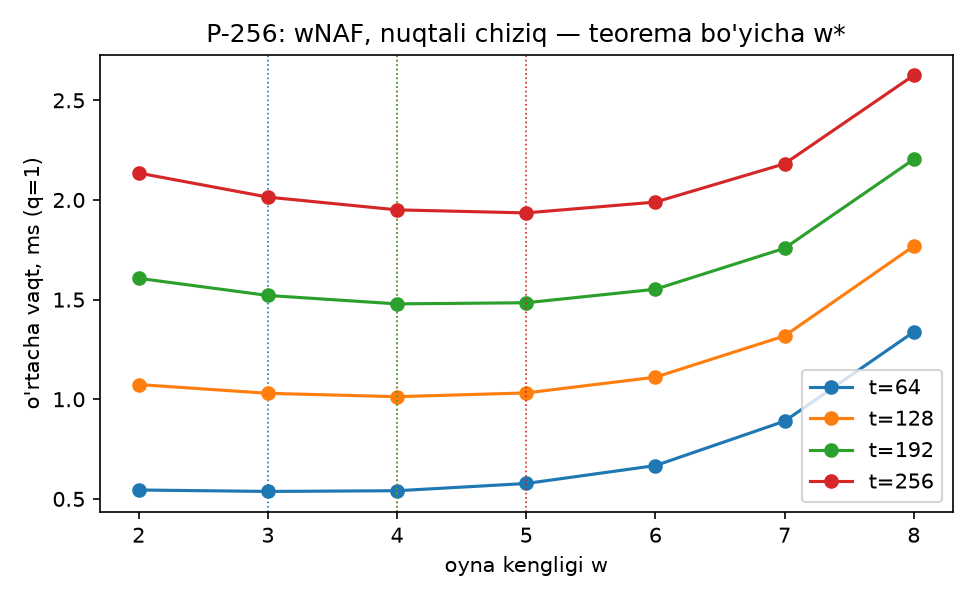

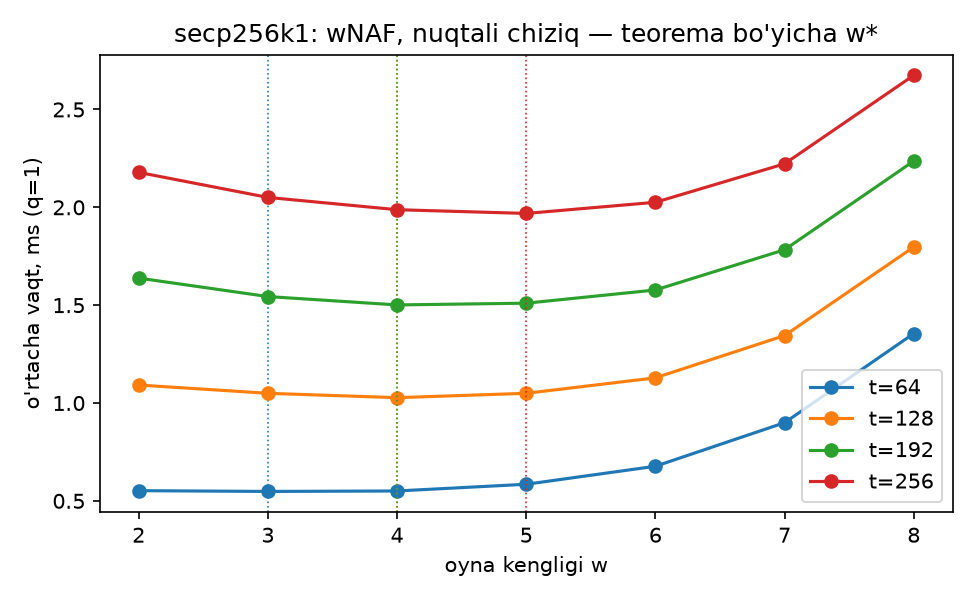

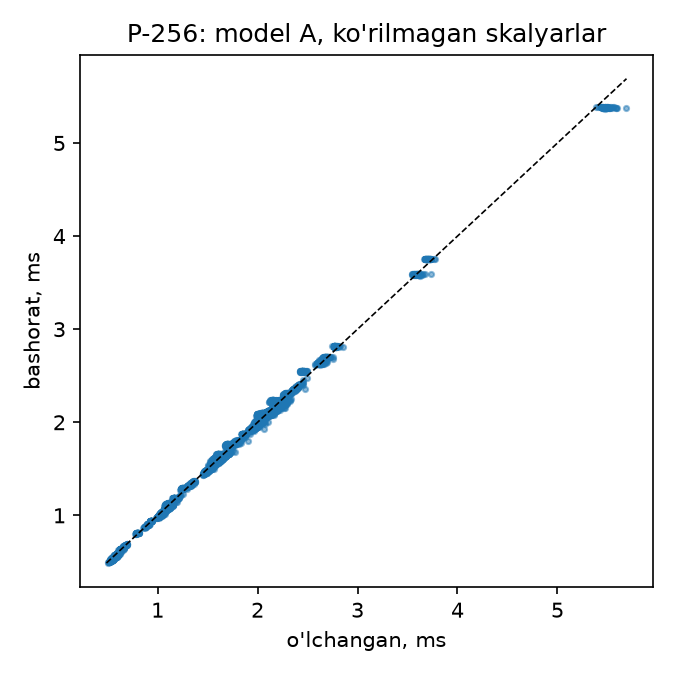

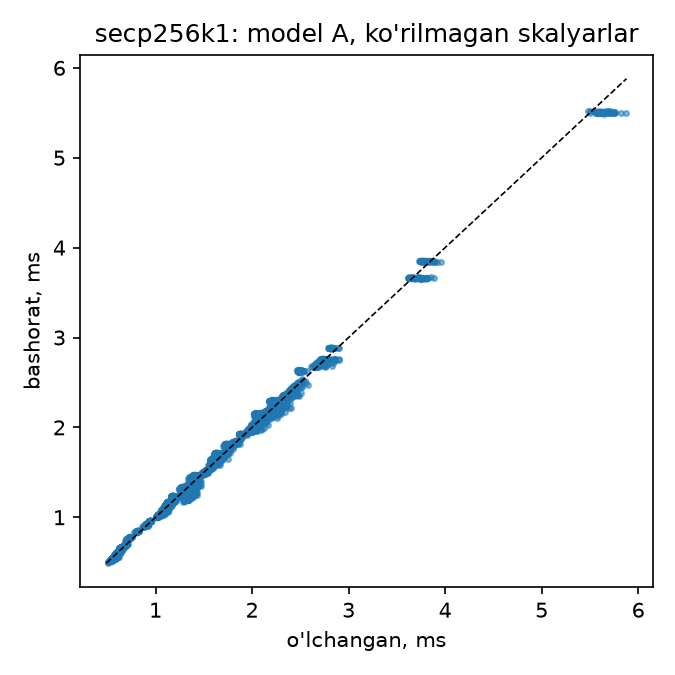

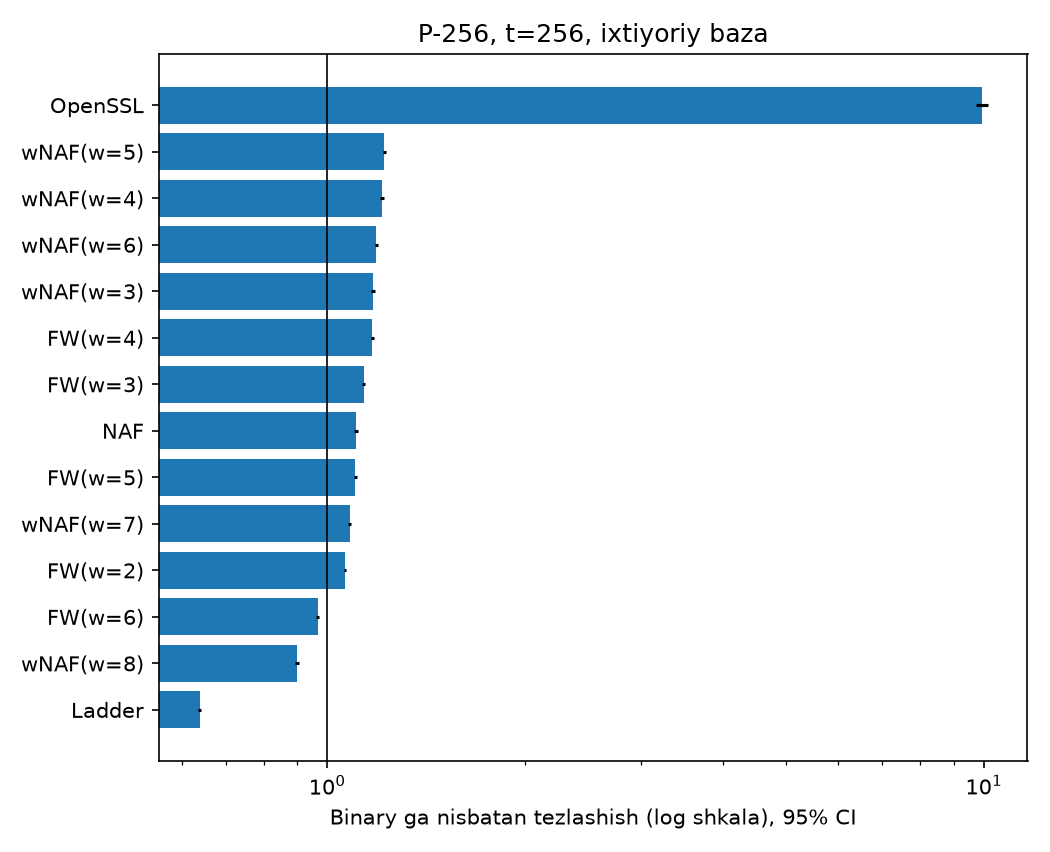

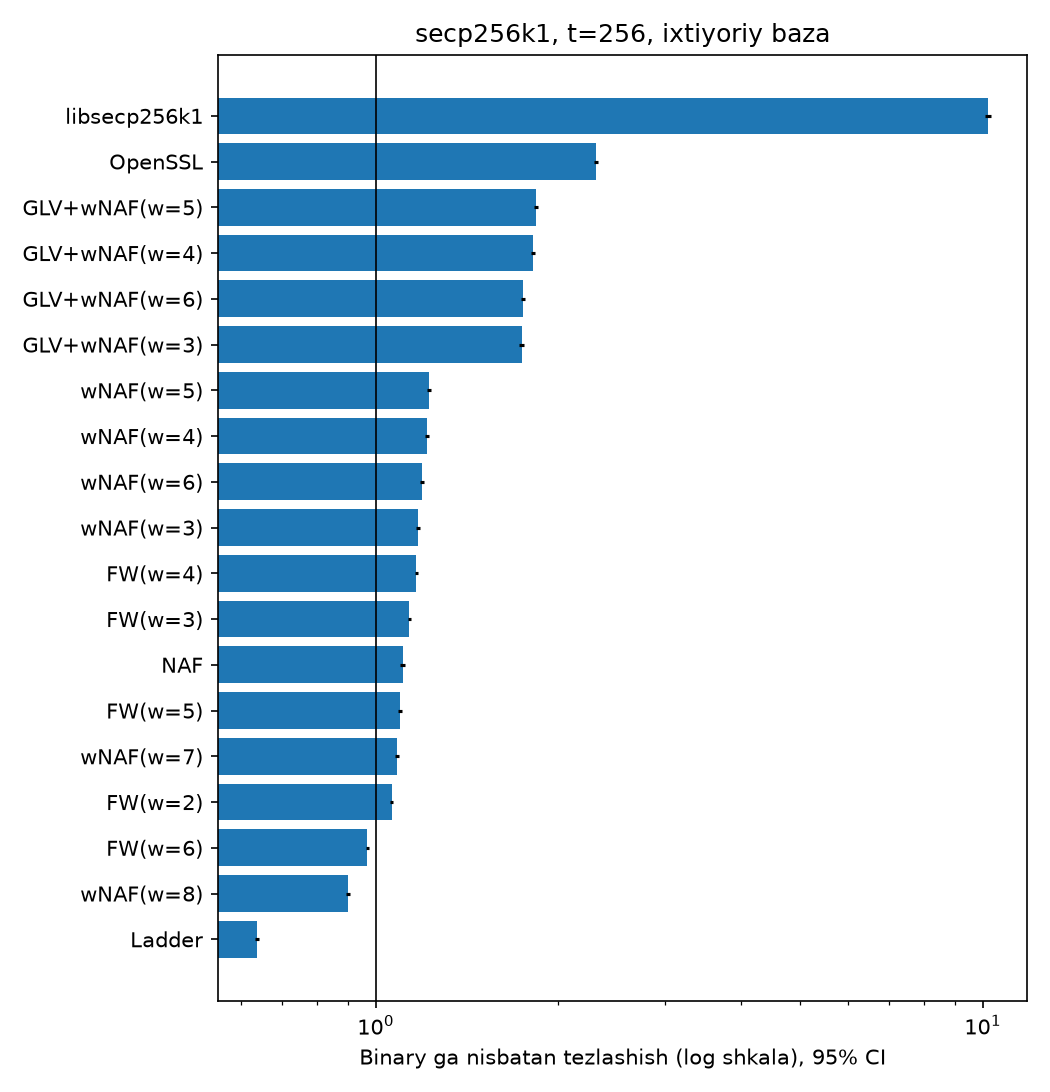

In [23]:
from IPython.display import Markdown, Image, display
import glob
display(Markdown(open(os.path.join(RES_DIR, "summary.md"), encoding="utf-8").read()))
for f in sorted(glob.glob(os.path.join(RES_DIR, "fig_*.png"))):
    display(Image(filename=f))